# Fase 1: Penalaan Parameter PSO untuk Alokasi Dana Saham LQ45

Lanjutan dari notebook PSO. Di sana PSO dengan parameter awal PDF (inersia 0,7, $c_1 = c_2 = 1{,}5$, $v_{maks} = 0{,}2$) terbukti
**lebih lemah dari GA** dan rentan **konvergen dini**. PDF rencana menetapkan Fase 1 untuk menala parameter sebelum perbandingan utama:

> *Tiap metaheuristik ditala pada satu konfigurasi tengah (K = 7, σ_max = 1,5×), dengan grid kecil: … PSO (w × c). Setiap titik grid
> dijalankan 30 kali; pilih konfigurasi dengan median R tertinggi dan variansi terendah. Parameter terpilih dibekukan sebelum Fase 2.*
> Penalaan hanya memakai **data latih jendela pertama**.

| Bagian | Isi |
|---|---|
| 1 | Fondasi bersama (dekoder, fitness, `Evaluator`) dan PSO, GA, brute force (kode sama dengan notebook sebelumnya) |
| 2 | Desain Fase 1: data, grid, aturan seleksi, dan pencegahan bias |
| 3 | **Tahap A:** grid $w \times c$ (18 titik × 30 run) |
| 4 | **Tahap B:** grid $v_{maks}$ pada $(w, c)$ terbaik |
| 5 | **Seleksi dan pembekuan** parameter, dibandingkan dengan parameter awal |
| 6 | **Validasi** pada data lain: PSO awal vs PSO terpilih vs GA |
| 7 | **Kesimpulan** |

**Cara menjalankan:** *Run All* (sekitar 5–6 menit). Lokal: dari root proyek atau `notebooks/`; Colab: cukup unggah notebook ini
(repositori diunduh otomatis bila data tidak ditemukan). Hasil grid disimpan ke `hasil/csv/pso_fase1_grid.csv` dan parameter beku ke
`hasil/csv/pso_parameter_beku.json`.

## 1. Fondasi bersama

In [1]:
import os, sys, time, subprocess
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# --- lokasi data: lokal (root proyek atau notebooks/) maupun Google Colab ---
REPO_URL = "https://github.com/hanscakrawangsa15/OptimasiPortofolioSaham.git"


def cari_root():
    for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "OptimasiPortofolioSaham"):
        if (p / "data" / "windows" / "kasus_tetap.npz").exists():
            return p
    return None


ROOT = cari_root()
if ROOT is None:                       # mis. Google Colab: hanya notebook ini yang ada -> unduh repo (publik)
    print("Data tidak ditemukan di folder kerja; mengunduh repositori dari GitHub ...")
    tujuan = Path.cwd() / "OptimasiPortofolioSaham"
    if not tujuan.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(tujuan)], check=True)
    ROOT = cari_root()
    assert ROOT is not None, "data/windows/*.npz tidak ada di repositori; jalankan python3 src/scrappingdata.py"

# --- parameter masalah (sesuai PDF rencana) ---
RF            = 0.05                      # return kas / risk-free, 5% per tahun
LOT           = 100                       # 100 lembar per lot
D             = 5_000_000.0               # modal (Rp)
K_LIST        = [2, 3, 5, 7, 10]          # batas jumlah saham
SIGMA_MULT    = 1.5                       # sigma_max = 1,5 x volatilitas portofolio 1/N
CAP           = 0.20                      # 20% per saham ...
CAP_MULAI_K   = 7                         # ... hanya untuk K >= 7
BUDGET        = 20_000                    # anggaran evaluasi per run
HISTORY_STEP  = 200                       # riwayat konvergensi dicatat tiap 200 evaluasi

np.set_printoptions(precision=4, suppress=True, linewidth=120)
print("ROOT =", ROOT)
print(f"D = Rp {D:,.0f} | rf = {RF:.0%} | cap = {CAP:.0%} (K >= {CAP_MULAI_K}) | anggaran = {BUDGET:,} evaluasi")

ROOT = /home/hans/Dokumen/Semester 7 Sisfor/SC/SCProject
D = Rp 5,000,000 | rf = 5% | cap = 20% (K >= 7) | anggaran = 20,000 evaluasi


In [2]:
@dataclass(frozen=True)
class Problem:
    mu: np.ndarray            # (N,) return tahunan (return sederhana)
    cov: np.ndarray           # (N,N) kovarians tahunan
    price: np.ndarray         # (N,) harga raw (tanpa penyesuaian) pada hari beli
    D: float                  # modal (Rp)
    K: int                    # batas jumlah saham
    sigma_max: float          # batas volatilitas portofolio
    cap: float = 1.0          # batas bobot per saham; 1.0 = tanpa batas (K < 7)
    lot: int = 100
    rf: float = 0.05
    tickers: tuple = ()
    label: str = ""

    @property
    def n(self) -> int:                 # jumlah saham N
        return len(self.mu)

    @property
    def n_genes(self) -> int:           # panjang kromosom = 2N+1
        return 2 * self.n + 1

    @property
    def harga_lot(self) -> np.ndarray:  # biaya 1 lot tiap saham (Rp)
        return self.lot * self.price

    @property
    def layak_beli(self) -> np.ndarray: # saham yang 1 lot-nya muat dalam D x cap
        return self.harga_lot <= self.D * self.cap

    @property
    def vol(self) -> np.ndarray:        # volatilitas tahunan tiap saham
        return np.sqrt(np.diag(self.cov))


@dataclass
class Result:
    lots: np.ndarray          # (N,) lot terbaik (bilangan bulat)
    R: float                  # return ekspektasi (in-sample)
    sigma: float              # volatilitas portofolio
    viol: float               # max(0, sigma - sigma_max); 0 bila layak
    feasible: bool
    history: list             # [(n_eval, R terbaik yang layak)] tiap 200 evaluasi
    n_eval: int
    seconds: float
    seed: int
    x: np.ndarray = None      # kromosom terbaik
    n_eval_best: int = 0      # evaluasi ke-berapa solusi terbaik ditemukan
    status: str = ""
    trace: dict = None        # jejak per generasi (opsional, untuk visualisasi proses GA)


def muat_jendela(nama):
    # Baca data/windows/<nama>.npz (dibuat oleh src/scrappingdata.py): statistik latih, harga beli, sigma_max.
    z = np.load(ROOT / "data" / "windows" / f"{nama}.npz", allow_pickle=False)
    return dict(
        tickers=[str(t) for t in z["tickers"]],
        tanggal_latih_awal=str(z["tanggal_latih_awal"]), tanggal_latih_akhir=str(z["tanggal_latih_akhir"]),
        tanggal_uji_awal=str(z["tanggal_uji_awal"]), tanggal_uji_akhir=str(z["tanggal_uji_akhir"]),
        mu=z["mu"], cov=z["cov"], harga_beli=z["harga_beli"],
        return_uji=z["return_uji"], tanggal_uji=[str(t) for t in z["tanggal_uji"]],   # hanya untuk evaluasi; TIDAK masuk Problem
        vol_benchmark=float(z["vol_benchmark"]),
        sigma_max={float(m): float(v) for m, v in zip(z["sigma_mult"], z["sigma_max"])})


def buat_problem(w, K, D=D, mult=SIGMA_MULT, label=""):
    return Problem(
        mu=w["mu"], cov=w["cov"], price=w["harga_beli"], D=D, K=K,
        sigma_max=w["sigma_max"][mult],
        cap=CAP if K >= CAP_MULAI_K else 1.0,
        lot=LOT, rf=RF, tickers=tuple(t.replace(".JK", "") for t in w["tickers"]), label=label)


# 5 jendela walk-forward + 1 kasus tetap
NAMA_DATA = ["kasus_tetap", "jendela_1", "jendela_2", "jendela_3", "jendela_4", "jendela_5"]
DATA = {nama: muat_jendela(nama) for nama in NAMA_DATA}

w = DATA["kasus_tetap"]
print("Kasus tetap : latih", w["tanggal_latih_awal"], "s.d.", w["tanggal_latih_akhir"],
      "| uji", w["tanggal_uji_awal"], "s.d.", w["tanggal_uji_akhir"])
print("Jumlah saham:", len(w["tickers"]), "| sigma_max (1,5x) =", round(w["sigma_max"][SIGMA_MULT], 4))
print()
print(f"{'Data':<12}{'tgl beli':<12}{'sigma_max':>10}{'vol 1/N':>10}")
for nama, d in DATA.items():
    print(f"{nama:<12}{d['tanggal_latih_akhir']:<12}{d['sigma_max'][SIGMA_MULT]:>10.4f}{d['vol_benchmark']:>10.4f}")

Kasus tetap : latih 2021-11-23 s.d. 2025-09-30 | uji 2025-10-01 s.d. 2026-09-30
Jumlah saham: 42 | sigma_max (1,5x) = 0.239

Data        tgl beli     sigma_max   vol 1/N
kasus_tetap 2025-09-30      0.2390    0.1593
jendela_1   2023-12-14      0.2048    0.1365
jendela_2   2024-07-09      0.1976    0.1318
jendela_3   2025-01-09      0.1962    0.1308
jendela_4   2025-07-31      0.2609    0.1739
jendela_5   2026-02-03      0.2717    0.1811


In [3]:
_EPS = 1e-12


def split(x, N):
    # Pisahkan kromosom menjadi (kunci, bobot mentah, gen kas).
    x = np.asarray(x, float)
    return x[..., :N], x[..., N:2 * N], x[..., 2 * N]


def _cap_redistribute(w, pilih, cap):
    # Langkah 4: potong bobot di atas cap, bagikan kelebihan ke saham terpilih yang belum penuh
    # (sebanding bobotnya), ulangi sampai stabil. Kelebihan yang tak bisa dibagi menjadi kas.
    w = w.copy()
    for _ in range(w.shape[1] + 1):
        lebih = w > cap + _EPS
        if not lebih.any():
            break
        excess = np.where(lebih, w - cap, 0.0).sum(1, keepdims=True)
        w = np.where(lebih, cap, w)
        bebas = pilih & (w < cap - _EPS)
        dasar = np.where(bebas, w, 0.0)
        ds = dasar.sum(1, keepdims=True)
        dasar = np.where(ds > 0, dasar, bebas.astype(float))   # semua bobot bebas nol -> sama rata
        ds = dasar.sum(1, keepdims=True)
        w = w + np.where(ds > 0, excess * dasar / np.where(ds > 0, ds, 1.0), 0.0)
    return np.minimum(w, cap)


def _bobot_target(X, P):
    # Langkah 1-4: kromosom (M, 2N+1) -> (himpunan terpilih (M,N) bool, bobot target (M,N), g0 (M,)).
    X = np.atleast_2d(np.asarray(X, float))
    M, N = X.shape[0], P.n
    if X.shape[1] != P.n_genes:
        raise ValueError(f"lebar kromosom {X.shape[1]} != n_genes {P.n_genes}")
    keys, raw, g0 = split(X, N)
    raw = np.clip(raw, 0.0, 1.0)
    g0 = np.clip(g0, 0.0, 1.0)

    # 1-2. saham terjangkau, lalu K kunci terbesar
    layak = P.layak_beli
    urut = np.argsort(-np.where(layak, keys, -np.inf), axis=1, kind="stable")[:, :P.K]
    pilih = np.zeros((M, N), bool)
    np.put_along_axis(pilih, urut, True, axis=1)
    pilih &= layak

    # 3. bobot awal: (1 - g0) dibagi sebanding bobot mentah (semua nol -> sama rata)
    r = np.where(pilih, raw, 0.0)
    s = r.sum(1, keepdims=True)
    sama = pilih / np.maximum(pilih.sum(1, keepdims=True), 1)
    frac = np.where(s > 0, r / np.where(s > 0, s, 1.0), sama)
    w = (1.0 - g0)[:, None] * frac

    # 4. batas per saham
    if P.cap < 1.0:
        w = _cap_redistribute(w, pilih, P.cap)
    return pilih, w, g0


def decode_batch(X, P):
    # Kromosom (M, 2N+1) -> (lots (M,N) int, bobot akhir (M,N), kas (M,)).
    pilih, w, g0 = _bobot_target(X, P)

    # 5-6. lot bulat, bobot akhir, kas
    lots = np.floor(w * P.D / P.harga_lot).astype(np.int64)
    w_akhir = lots * P.harga_lot / P.D
    kas = np.maximum(1.0 - w_akhir.sum(1), 0.0)
    return lots, w_akhir, kas


def decode(x, P):
    # Satu kromosom -> (lots (N,), bobot (N,), kas).
    lots, w, kas = decode_batch(np.asarray(x, float)[None, :], P)
    return lots[0], w[0], kas[0]


print("dekoder siap")

dekoder siap


In [4]:
def rp(x):
    # Format Rupiah Indonesia, mis. Rp 1.676.000
    return "Rp " + f"{x:,.0f}".replace(",", ".")


def rincian_kas(x, P):
    # Rincian dana dalam Rupiah untuk satu kromosom: dana terpakai, sisa kas akhir, dan tiga komponennya.
    x = np.asarray(x, float)
    pilih, w, g0 = _bobot_target(x[None, :], P)
    lots, _, _ = decode_batch(x[None, :], P)
    terpakai = float((lots[0] * P.harga_lot).sum())
    kas_akhir = P.D - terpakai
    kas_sengaja = float(g0[0] * P.D)
    kas_cap = max(0.0, float(P.D * (1.0 - g0[0] - w[0].sum())))
    kas_bulat = kas_akhir - kas_sengaja - kas_cap                 # sisanya = efek pembulatan lot
    assert kas_bulat >= -1e-6, "sisa pembulatan tidak boleh negatif"
    return dict(modal=P.D, terpakai=terpakai, kas_akhir=kas_akhir, kas_sengaja=kas_sengaja,
                kas_cap=kas_cap, kas_pembulatan=max(kas_bulat, 0.0))


def tabel_portofolio(P, lots, x=None, judul=""):
    # Cetak posisi saham (lot, lembar, harga, nilai Rp, bobot) dan sisa kas dalam Rupiah.
    nilai = lots * P.harga_lot
    idx = np.where(lots > 0)[0]
    idx = idx[np.argsort(-nilai[idx])]
    if judul:
        print(judul)
    print(f"  {'Saham':<7}{'Lot':>5}{'Lembar':>8}{'Harga/lembar':>14}{'Nilai posisi':>16}{'Bobot':>8}")
    for i in idx:
        print(f"  {P.tickers[i]:<7}{lots[i]:>5}{lots[i] * P.lot:>8}{rp(P.price[i]):>14}{rp(nilai[i]):>16}{nilai[i] / P.D:>8.1%}")
    terpakai = nilai.sum()
    kas = P.D - terpakai
    print(f"  {'-' * 58}")
    print(f"  {'Modal':<28}{rp(P.D):>16}")
    print(f"  {'Dana terpakai':<28}{rp(terpakai):>16}{terpakai / P.D:>8.1%}")
    print(f"  {'SISA KAS AKHIR':<28}{rp(kas):>16}{kas / P.D:>8.1%}")
    if x is not None:
        r = rincian_kas(x, P)
        print(f"    - kas sengaja (g0 x D)           {rp(r['kas_sengaja']):>13}")
        print(f"    - kelebihan cap / tak teralokasi {rp(r['kas_cap']):>13}")
        print(f"    - sisa pembulatan lot            {rp(r['kas_pembulatan']):>13}")


# contoh: jendela 3, K = 2, BRIS + ISAT (contoh yang sama dengan bagian 6)
P = buat_problem(DATA["jendela_3"], 2)
i_bris, i_isat = P.tickers.index("BRIS"), P.tickers.index("ISAT")
x = np.zeros(P.n_genes)
x[i_bris] = x[i_isat] = 1.0
x[P.n + i_bris], x[P.n + i_isat] = 0.55, 0.45
x[-1] = 0.30
lots, w, kas = decode(x, P)
tabel_portofolio(P, lots, x, judul="Contoh: jendela 3, K = 2 (g0 = 0,30)")

r = rincian_kas(x, P)
assert abs(r["kas_sengaja"] + r["kas_cap"] + r["kas_pembulatan"] - r["kas_akhir"]) < 1e-6
assert abs(r["kas_akhir"] - (kas * P.D)) < 1e-6 and abs(r["kas_sengaja"] - 1_500_000) < 1e-6
print("\nuji rincian kas: lulus (tiga komponen berjumlah sisa kas akhir)")

# demonstrasi kelebihan cap: K = 7 dengan cap 10% (7 x 10% = 70%), sehingga 30% dana tak bisa dialokasikan
from dataclasses import replace
Pc = replace(buat_problem(DATA["kasus_tetap"], 7), cap=0.10)
rng = np.random.default_rng(5)
xc = rng.random(Pc.n_genes); xc[-1] = 0.0                          # g0 = 0: tidak ada kas sengaja
lc, _, _ = decode(xc, Pc)
tabel_portofolio(Pc, lc, xc, judul="\nDemonstrasi: kasus tetap, K = 7, cap 10%, g0 = 0")
rc = rincian_kas(xc, Pc)
assert abs(rc["kas_sengaja"] + rc["kas_cap"] + rc["kas_pembulatan"] - rc["kas_akhir"]) < 1e-6
assert rc["kas_cap"] > 0.29 * Pc.D, "7 saham x cap 10% hanya menampung 70% dana"
print("\nuji kelebihan cap: lulus (30% dana tak tertampung -> menjadi kas)")

Contoh: jendela 3, K = 2 (g0 = 0,30)
  Saham    Lot  Lembar  Harga/lembar    Nilai posisi   Bobot
  BRIS       7     700      Rp 2.700    Rp 1.890.000   37.8%
  ISAT       6     600      Rp 2.390    Rp 1.434.000   28.7%
  ----------------------------------------------------------
  Modal                           Rp 5.000.000
  Dana terpakai                   Rp 3.324.000   66.5%
  SISA KAS AKHIR                  Rp 1.676.000   33.5%
    - kas sengaja (g0 x D)            Rp 1.500.000
    - kelebihan cap / tak teralokasi          Rp 0
    - sisa pembulatan lot               Rp 176.000

uji rincian kas: lulus (tiga komponen berjumlah sisa kas akhir)

Demonstrasi: kasus tetap, K = 7, cap 10%, g0 = 0
  Saham    Lot  Lembar  Harga/lembar    Nilai posisi   Bobot
  BUKA      29    2900        Rp 170      Rp 493.000    9.9%
  CPIN       1     100      Rp 4.660      Rp 466.000    9.3%
  KLBF       4     400      Rp 1.130      Rp 452.000    9.0%
  JPFA       2     200      Rp 1.960      Rp 392.0

In [5]:
def hitung(lots, w, kas, P):
    # Objektif dan kendala risiko untuk sekumpulan portofolio (batch).
    R = w @ P.mu + kas * P.rf
    var = np.einsum("ij,jk,ik->i", w, P.cov, w)
    sigma = np.sqrt(np.maximum(var, 0.0))
    viol = np.maximum(0.0, sigma - P.sigma_max)
    return R, sigma, viol


# ---------------- aturan Deb ----------------
def deb_urut(R, viol):
    # Indeks dari terbaik ke terburuk: layak dulu (R besar), lalu tak layak (viol kecil).
    layak = viol <= 0.0
    return np.lexsort((-R, np.where(layak, 0.0, viol), ~layak))


def deb_rank(R, viol):
    # Peringkat tiap individu (0 = terbaik).
    urut = deb_urut(R, viol)
    rank = np.empty(len(urut), dtype=np.int64)
    rank[urut] = np.arange(len(urut))
    return rank


def deb_better(a, b):
    # a, b = (R, viol). True bila a lebih baik daripada b menurut aturan Deb.
    (Ra, va), (Rb, vb) = a, b
    if va <= 0 and vb <= 0:
        return Ra > Rb
    if va <= 0:
        return True
    if vb <= 0:
        return False
    return va < vb


class AnggaranHabis(Exception):
    pass


class Evaluator:
    # Pintu tunggal evaluasi: dekode + objektif + risiko + anggaran + solusi terbaik + riwayat.

    def __init__(self, P, budget=BUDGET, step=HISTORY_STEP):
        self.P, self.budget, self.step = P, budget, step
        self.n_eval = 0
        self.n_eval_best = 0
        self.best = None                 # dict: x, lots, R, sigma, viol
        self.history = []                # [(n_eval, R terbaik yang layak atau nan)]

    def evaluate(self, X):
        X = np.atleast_2d(np.asarray(X, float))
        if X.shape[1] != self.P.n_genes:
            raise ValueError(f"lebar kromosom {X.shape[1]} != n_genes {self.P.n_genes}")
        if self.n_eval + len(X) > self.budget:
            raise AnggaranHabis(f"{self.n_eval} + {len(X)} > anggaran {self.budget}")
        hasil_R, hasil_s, hasil_v = [], [], []
        i = 0
        while i < len(X):                                   # pecah di kelipatan `step` agar riwayat tepat
            batas = self.step - (self.n_eval % self.step)
            chunk = X[i:i + batas]
            lots, w, kas = decode_batch(chunk, self.P)
            R, s, v = hitung(lots, w, kas, self.P)
            j = deb_urut(R, v)[0]
            cand = (R[j], v[j])
            if self.best is None or deb_better(cand, (self.best["R"], self.best["viol"])):
                self.best = dict(x=chunk[j].copy(), lots=lots[j].copy(), R=R[j], sigma=s[j], viol=v[j])
                self.n_eval_best = self.n_eval + j + 1
            self.n_eval += len(chunk)
            if self.n_eval % self.step == 0:
                b = self.best
                self.history.append((self.n_eval, b["R"] if b["viol"] <= 0 else np.nan))
            hasil_R.append(R); hasil_s.append(s); hasil_v.append(v)
            i += len(chunk)
        return np.concatenate(hasil_R), np.concatenate(hasil_s), np.concatenate(hasil_v)

    def hasil(self, seed, seconds):
        b = self.best
        return Result(lots=b["lots"], R=float(b["R"]), sigma=float(b["sigma"]), viol=float(b["viol"]),
                      feasible=bool(b["viol"] <= 0), history=list(self.history), n_eval=self.n_eval,
                      seconds=seconds, seed=seed, x=b["x"], n_eval_best=self.n_eval_best)


print("fitness dan Evaluator siap")

fitness dan Evaluator siap


In [6]:
def acak_kromosom(P, rng, m, g0_maks=1.0):
    X = rng.random((m, P.n_genes))
    X[:, -1] = rng.uniform(0.0, g0_maks, m)
    return X


# ---------- 1. invarian dekoder ----------
rng = np.random.default_rng(12345)
for nama in ["kasus_tetap", "jendela_3"]:
    for K in K_LIST:
        P = buat_problem(DATA[nama], K)
        X = acak_kromosom(P, rng, 10_000)
        lots, w, kas = decode_batch(X, P)
        biaya = P.harga_lot
        assert lots.dtype.kind == "i" and (lots >= 0).all(), "lot harus bilangan bulat >= 0"
        assert ((lots > 0).sum(1) <= K).all(), "jumlah saham melebihi K"
        assert (w <= P.cap + 1e-9).all(), "bobot melebihi cap"
        assert ((lots * biaya).sum(1) <= P.D * (1 + 1e-12)).all(), "dana terpakai melebihi D"
        assert (kas >= 0).all() and np.allclose(w.sum(1) + kas, 1.0), "bobot + kas harus = 1"
        assert (lots[:, ~P.layak_beli] == 0).all(), "saham tak terjangkau terpilih"
print("1. invarian dekoder: lulus (2 data x 5 nilai K x 10.000 kromosom)")


# ---------- 2. dekoder referensi (loop biasa, ditulis terpisah) ----------
def decode_referensi(x, P):
    N = P.n
    keys, raw, g0 = x[:N], np.clip(x[N:2 * N], 0, 1), min(max(x[2 * N], 0.0), 1.0)
    kandidat = [i for i in range(N) if P.harga_lot[i] <= P.D * P.cap]
    kandidat.sort(key=lambda i: (-keys[i], i))
    S = kandidat[:P.K]
    w = np.zeros(N)
    if S:
        tot = sum(raw[i] for i in S)
        for i in S:
            w[i] = (1 - g0) * (raw[i] / tot if tot > 0 else 1.0 / len(S))
    if P.cap < 1.0:
        for _ in range(N + 1):
            lebih = [i for i in S if w[i] > P.cap + _EPS]
            if not lebih:
                break
            excess = sum(w[i] - P.cap for i in lebih)
            for i in lebih:
                w[i] = P.cap
            bebas = [i for i in S if w[i] < P.cap - _EPS]
            if not bebas:
                continue
            dasar = [w[i] for i in bebas]
            if sum(dasar) <= 0:
                dasar = [1.0] * len(bebas)
            for i, b in zip(bebas, dasar):
                w[i] += excess * b / sum(dasar)
    lots = np.array([int(np.floor(w[i] * P.D / P.harga_lot[i])) for i in range(N)])
    return lots


rng = np.random.default_rng(7)
for K in K_LIST:
    P = buat_problem(DATA["jendela_3"], K)
    X = acak_kromosom(P, rng, 1500)
    lots_v, _, _ = decode_batch(X, P)
    for x, lv in zip(X, lots_v):
        assert (decode_referensi(x, P) == lv).all(), f"beda dari referensi (K={K})"
    lots_1, _, _ = decode(X[0], P)
    assert (lots_1 == lots_v[0]).all()
print("2. dekoder vektor = dekoder referensi: lulus (5 nilai K x 1.500 kromosom)")


# ---------- 3. kasus degenerat dan gen kas ----------
P = buat_problem(DATA["kasus_tetap"], 2)
x = np.zeros(P.n_genes); x[-1] = 1.0                       # g0 = 1 -> semua kas
lots, w, kas = decode(x, P)
R, s, v = hitung(lots[None], w[None], np.array([kas]), P)
assert lots.sum() == 0 and abs(kas - 1) < 1e-12 and abs(R[0] - RF) < 1e-12 and s[0] == 0 and v[0] == 0
print("3a. g0 = 1: semua kas, R = r_f, sigma = 0, layak")

P1 = buat_problem(DATA["kasus_tetap"], 1)
rng = np.random.default_rng(3)
for _ in range(200):
    x = rng.random(P1.n_genes); x[-1] = 0.0                # g0 = 0 setara versi 2N
    lots, w, kas = decode(x, P1)
    assert (lots > 0).sum() == 1
    i = int(np.argmax(lots))
    assert kas < P1.harga_lot[i] / P1.D + 1e-12, "sisa dana harus kurang dari satu lot"
print("3b. K = 1, g0 = 0: satu saham, sisa dana kurang dari satu lot")


# ---------- 4. aturan Deb dan Evaluator ----------
R_ = np.array([0.30, 0.20, 0.50, 0.40, 0.10])
v_ = np.array([0.0, 0.0, 0.05, 0.01, 0.0])
assert list(deb_urut(R_, v_)) == [0, 1, 4, 3, 2]            # layak (R turun), lalu tak layak (viol naik)
assert deb_better((0.2, 0.0), (0.9, 0.01)) and not deb_better((0.9, 0.01), (0.2, 0.0))
assert deb_better((0.3, 0.0), (0.2, 0.0)) and deb_better((0.1, 0.01), (0.9, 0.05))
assert list(deb_rank(R_, v_)) == [0, 1, 4, 3, 2]

P = buat_problem(DATA["kasus_tetap"], 5)
ev = Evaluator(P, budget=1000)
rng = np.random.default_rng(1)
ev.evaluate(acak_kromosom(P, rng, 450))
ev.evaluate(acak_kromosom(P, rng, 150))
assert ev.n_eval == 600 and [h[0] for h in ev.history] == [200, 400, 600]
bests = [h[1] for h in ev.history if not np.isnan(h[1])]
assert all(b2 >= b1 - 1e-12 for b1, b2 in zip(bests, bests[1:])), "R terbaik yang layak tidak boleh turun"
try:
    ev.evaluate(acak_kromosom(P, rng, 401)); raise SystemExit("seharusnya AnggaranHabis")
except AnggaranHabis:
    pass
try:
    ev.evaluate(np.zeros((1, P.n_genes - 1))); raise SystemExit("seharusnya ValueError")
except ValueError:
    pass
print("4. aturan Deb dan Evaluator (anggaran, riwayat tiap 200, lebar kromosom): lulus")

1. invarian dekoder: lulus (2 data x 5 nilai K x 10.000 kromosom)


2. dekoder vektor = dekoder referensi: lulus (5 nilai K x 1.500 kromosom)
3a. g0 = 1: semua kas, R = r_f, sigma = 0, layak
3b. K = 1, g0 = 0: satu saham, sisa dana kurang dari satu lot
4. aturan Deb dan Evaluator (anggaran, riwayat tiap 200, lebar kromosom): lulus


In [7]:
def init_population(P, rng, n, n_seed=0):
    # Populasi awal (n, 2N+1): acak seragam, g0 di [0; 0,5]; n_seed baris pertama disemai top-K.
    N = P.n
    X = np.empty((n, P.n_genes))
    X[:, :N] = rng.random((n, N))
    X[:, N:2 * N] = rng.random((n, N))
    X[:, 2 * N] = rng.uniform(0.0, 0.5, n)
    skor = (P.mu - P.rf) / P.vol                                  # heuristik: return lebih per unit risiko
    skor = (skor - skor.min()) / (skor.max() - skor.min() + 1e-12)
    for i in range(min(n_seed, n)):
        X[i, :N] = np.clip(skor + rng.normal(0.0, 0.05, N), 0.0, 1.0)
        X[i, N:2 * N] = rng.uniform(0.3, 1.0, N)
        X[i, 2 * N] = rng.uniform(0.0, 0.1)
    return X


PSO_PARAM = dict(n=40, w=0.7, c1=1.5, c2=1.5, v_maks=0.2)


def deb_lebih_baik(R1, v1, R2, v2):
    # Aturan Deb versi vektor: True di mana (R1, v1) lebih baik daripada (R2, v2).
    l1, l2 = v1 <= 0.0, v2 <= 0.0
    return np.where(l1 & l2, R1 > R2, np.where(l1, True, np.where(l2, False, v1 < v2)))


def pso_run(P, budget=BUDGET, seed=0, trace=False, **kw):
    # Satu run PSO. trace=True menyimpan keadaan swarm tiap iterasi (untuk visualisasi proses PSO).
    prm = {**PSO_PARAM, **kw}
    rng = np.random.default_rng(seed)
    ev = Evaluator(P, budget)
    t0 = time.perf_counter()
    n, d, vm = prm["n"], P.n_genes, prm["v_maks"]
    kunci = ("R", "sigma", "viol", "g0", "kas", "n_unik", "R_gbest", "gb_R", "gb_sigma", "g0_gbest", "kas_gbest",
             "lots_terbaik", "kecepatan", "jarak", "x_min", "x_max")
    rec = {k: [] for k in kunci} if trace else None

    x = init_population(P, rng, n, n_seed=0)                  # posisi awal acak seragam
    vel = rng.uniform(-vm, vm, (n, d))
    R, s, vi = ev.evaluate(x)
    pb_x, pb_R, pb_s, pb_v = x.copy(), R.copy(), s.copy(), vi.copy()    # pbest tiap partikel
    g = int(deb_urut(pb_R, pb_v)[0])                                    # gbest = pbest terbaik menurut Deb

    def catat():
        if rec is None:
            return
        lots, _, kas = decode_batch(x, P)
        lg, _, kg = decode(pb_x[g], P)
        rec["R"].append(R.copy()); rec["sigma"].append(s.copy()); rec["viol"].append(vi.copy())
        rec["g0"].append(np.clip(x[:, -1], 0.0, 1.0)); rec["kas"].append(kas)
        rec["n_unik"].append(len({tuple(np.where(l > 0)[0]) for l in lots}))
        rec["R_gbest"].append(pb_R[g] if pb_v[g] <= 0 else np.nan)
        rec["gb_R"].append(pb_R[g]); rec["gb_sigma"].append(pb_s[g])
        rec["g0_gbest"].append(float(np.clip(pb_x[g][-1], 0.0, 1.0))); rec["kas_gbest"].append(kg)
        rec["lots_terbaik"].append(lg)
        rec["kecepatan"].append(float(np.abs(vel).mean()))
        rec["jarak"].append(float(np.linalg.norm(x - pb_x[g], axis=1).mean()))
        rec["x_min"].append(float(x.min())); rec["x_max"].append(float(x.max()))

    catat()
    while ev.n_eval + n <= budget:
        r1, r2 = rng.random((n, d)), rng.random((n, d))
        vel = prm["w"] * vel + prm["c1"] * r1 * (pb_x - x) + prm["c2"] * r2 * (pb_x[g] - x)
        vel = np.clip(vel, -vm, vm)
        x = x + vel
        luar = (x < 0.0) | (x > 1.0)
        x = np.clip(x, 0.0, 1.0)
        vel = np.where(luar, 0.0, vel)                         # menabrak batas: kecepatan komponen itu dinolkan
        R, s, vi = ev.evaluate(x)
        lebih = deb_lebih_baik(R, vi, pb_R, pb_v)              # pbest diperbarui menurut aturan Deb
        pb_x[lebih], pb_R[lebih], pb_s[lebih], pb_v[lebih] = x[lebih], R[lebih], s[lebih], vi[lebih]
        g = int(deb_urut(pb_R, pb_v)[0])
        catat()

    hasil = ev.hasil(seed, time.perf_counter() - t0)
    if trace:
        hasil.trace = {k: np.array(val) for k, val in rec.items()}
    return hasil


# ---------- uji ----------
rng = np.random.default_rng(0)
R1, R2 = rng.random(600).round(1), rng.random(600).round(1)                       # dibulatkan agar ada nilai kembar
v1 = np.where(rng.random(600) < 0.5, 0.0, rng.random(600).round(2))
v2 = np.where(rng.random(600) < 0.5, 0.0, rng.random(600).round(2))
vek = deb_lebih_baik(R1, v1, R2, v2)
assert all(vek[i] == deb_better((R1[i], v1[i]), (R2[i], v2[i])) for i in range(600)), "Deb vektor harus sama dengan Deb skalar"

P = buat_problem(DATA["kasus_tetap"], 7)
a, b, c = pso_run(P, seed=11), pso_run(P, seed=11), pso_run(P, seed=12)
assert a.n_eval == BUDGET and np.array_equal(a.lots, b.lots) and a.R == b.R, "seed sama harus identik"
assert not np.array_equal(a.x, c.x), "seed beda harus beda"
assert len(a.history) == BUDGET // HISTORY_STEP
t = pso_run(P, seed=11, trace=True)
assert t.R == a.R and np.array_equal(t.lots, a.lots), "trace tidak boleh mengubah hasil"
tr = t.trace
assert tr["R"].shape == (BUDGET // PSO_PARAM["n"], PSO_PARAM["n"]), "500 iterasi x 40 partikel"
assert tr["x_min"].min() >= 0.0 and tr["x_max"].max() <= 1.0, "posisi harus di [0,1]"
rg = tr["R_gbest"][~np.isnan(tr["R_gbest"])]
assert (np.diff(rg) >= -1e-12).all(), "R gbest yang layak tidak boleh turun"
print("uji PSO lulus: Deb vektor = Deb skalar, anggaran tepat 20.000, reprodusibel, posisi di [0,1], gbest monoton")
print(f"PSO K=7 kasus tetap: R = {a.R:.4f}, sigma = {a.sigma:.4f} (batas {P.sigma_max:.4f}), "
      f"layak = {a.feasible}, {a.n_eval:,} evaluasi, {a.seconds:.2f} detik")

uji PSO lulus: Deb vektor = Deb skalar, anggaran tepat 20.000, reprodusibel, posisi di [0,1], gbest monoton
PSO K=7 kasus tetap: R = 0.2793, sigma = 0.2365 (batas 0.2390), layak = True, 20,000 evaluasi, 0.25 detik


In [8]:
def brute_force_k2(P):
    # Optimum sejati untuk K <= 2: semua saham tunggal dan pasangan, semua kombinasi lot (n_i >= 1).
    # Mengembalikan dict {aturan_kas: (R, {saham: lot}, kas)}.
    mu, cov, c, D, rf = P.mu, P.cov, P.harga_lot, P.D, P.rf
    N = P.n
    terbaik = {"kas bebas": (-9.0, None, None), "kas <= 5%": (-9.0, None, None),
               "kas hanya dari pembulatan": (-9.0, None, None)}

    def catat(nama, R, lot, kas):
        if R > terbaik[nama][0]:
            terbaik[nama] = (float(R), lot, float(kas))

    def aturan(layak, kas, biaya_min):
        return {"kas bebas": layak, "kas <= 5%": layak & (kas <= 0.05),
                "kas hanya dari pembulatan": layak & (kas * D < biaya_min)}

    for i in range(N):
        n1 = np.arange(1, int(D // c[i]) + 1)
        w1 = n1 * c[i] / D
        kas = 1 - w1
        sigma = w1 * np.sqrt(cov[i, i])
        R = w1 * mu[i] + kas * rf
        for nama, m in aturan(sigma <= P.sigma_max, kas, c[i]).items():
            if m.any():
                k = np.argmax(np.where(m, R, -9)); catat(nama, R[k], {P.tickers[i]: int(n1[k])}, kas[k])
        for j in range(i + 1, N):
            a = np.arange(1, int(D // c[i]) + 1)[:, None]
            b = np.arange(1, int(D // c[j]) + 1)[None, :]
            ok = a * c[i] + b * c[j] <= D
            w1, w2 = a * c[i] / D, b * c[j] / D
            kas = 1 - w1 - w2
            var = w1 ** 2 * cov[i, i] + w2 ** 2 * cov[j, j] + 2 * w1 * w2 * cov[i, j]
            R = w1 * mu[i] + w2 * mu[j] + kas * rf
            layak = ok & (np.sqrt(var) <= P.sigma_max)
            for nama, m in aturan(layak, kas, c[i] + c[j]).items():
                if m.any():
                    idx = np.unravel_index(np.argmax(np.where(m, R, -9)), R.shape)
                    catat(nama, R[idx], {P.tickers[i]: int(a[idx[0], 0]), P.tickers[j]: int(b[0, idx[1]])}, kas[idx])
    return terbaik


t0 = time.perf_counter()
BF = {nama: brute_force_k2(buat_problem(DATA[nama], 2)) for nama in ["kasus_tetap", "jendela_3", "jendela_5"]}
print(f"brute force selesai dalam {time.perf_counter() - t0:.1f} detik\n")
print(f"{'data':<13}{'aturan kas':<28}{'R*':>8}{'kas':>7}   portofolio optimum")
for nama, hasil in BF.items():
    for aturan_kas, (R, lot, kas) in hasil.items():
        print(f"{nama:<13}{aturan_kas:<28}{R:>8.4f}{kas:>7.3f}   {lot}")
    print()

brute force selesai dalam 0.2 detik

data         aturan kas                        R*    kas   portofolio optimum
kasus_tetap  kas bebas                     0.2966  0.242   {'BRPT': 4, 'ITMG': 1}
kasus_tetap  kas <= 5%                     0.2115  0.014   {'BMRI': 6, 'ITMG': 1}
kasus_tetap  kas hanya dari pembulatan     0.2966  0.242   {'BRPT': 4, 'ITMG': 1}

jendela_3    kas bebas                     0.2817  0.335   {'BRIS': 7, 'ISAT': 6}
jendela_3    kas <= 5%                     0.2067  0.018   {'INDF': 4, 'ISAT': 8}
jendela_3    kas hanya dari pembulatan     0.2407  0.172   {'BRIS': 7, 'INDF': 3}

jendela_5    kas bebas                     0.5114  0.038   {'ANTM': 4, 'PGAS': 15}
jendela_5    kas <= 5%                     0.5114  0.038   {'ANTM': 4, 'PGAS': 15}
jendela_5    kas hanya dari pembulatan     0.5114  0.038   {'ANTM': 4, 'PGAS': 15}



In [9]:
GA_PARAM = dict(pop=100, turnamen=3, p_sbx=0.9, eta=15.0, sigma_mut=0.1,
                p_swap=0.2, elitisme=2, n_seed=10)


def init_population(P, rng, n, n_seed=0):
    # Populasi awal (n, 2N+1): acak seragam, g0 di [0; 0,5]; n_seed baris pertama disemai top-K.
    N = P.n
    X = np.empty((n, P.n_genes))
    X[:, :N] = rng.random((n, N))
    X[:, N:2 * N] = rng.random((n, N))
    X[:, 2 * N] = rng.uniform(0.0, 0.5, n)
    skor = (P.mu - P.rf) / P.vol                                  # heuristik: return lebih per unit risiko
    skor = (skor - skor.min()) / (skor.max() - skor.min() + 1e-12)
    for i in range(min(n_seed, n)):
        X[i, :N] = np.clip(skor + rng.normal(0.0, 0.05, N), 0.0, 1.0)
        X[i, N:2 * N] = rng.uniform(0.3, 1.0, N)
        X[i, 2 * N] = rng.uniform(0.0, 0.1)
    return X


def turnamen(rank, rng, n, k):
    # Seleksi turnamen ukuran k berdasarkan peringkat Deb (rank kecil = baik).
    cand = rng.integers(0, len(rank), size=(n, k))
    return cand[np.arange(n), np.argmin(rank[cand], axis=1)]


def sbx(p1, p2, eta, rng):
    u = rng.random(p1.shape)
    beta = np.where(u <= 0.5, (2 * u) ** (1 / (eta + 1)), (1 / (2 * (1 - u))) ** (1 / (eta + 1)))
    return (0.5 * ((1 + beta) * p1 + (1 - beta) * p2),
            0.5 * ((1 - beta) * p1 + (1 + beta) * p2))


def mutasi_swap(kids, P, p_swap, rng):
    # Tukar kunci satu saham terpilih dengan satu saham terjangkau di luar himpunan terpilih.
    N, K = P.n, P.K
    kand = np.where(P.layak_beli)[0]
    if len(kand) <= K:
        return
    for i in np.where(rng.random(len(kids)) < p_swap)[0]:
        urut = kand[np.argsort(-kids[i, kand], kind="stable")]
        a, b = urut[rng.integers(0, K)], urut[rng.integers(K, len(urut))]
        kids[i, a], kids[i, b] = kids[i, b], kids[i, a]


def ga_run(P, budget=BUDGET, seed=0, trace=False, **kw):
    # Satu run GA. trace=True menyimpan keadaan populasi tiap generasi (untuk visualisasi proses GA).
    prm = {**GA_PARAM, **kw}
    rng = np.random.default_rng(seed)
    ev = Evaluator(P, budget)
    t0 = time.perf_counter()
    n, N, E = prm["pop"], P.n, prm["elitisme"]
    rec = {k: [] for k in ("R", "sigma", "viol", "g0", "kas", "n_unik", "lots_terbaik")} if trace else None

    def catat(pop, R, s, v):
        if rec is None:
            return
        lots, _, kas = decode_batch(pop, P)
        rec["R"].append(R.copy()); rec["sigma"].append(s.copy()); rec["viol"].append(v.copy())
        rec["g0"].append(np.clip(pop[:, -1], 0.0, 1.0)); rec["kas"].append(kas)
        rec["n_unik"].append(len({tuple(np.where(l > 0)[0]) for l in lots}))
        rec["lots_terbaik"].append(lots[deb_urut(R, v)[0]])

    pop = init_population(P, rng, n, prm["n_seed"])
    R, s, v = ev.evaluate(pop)
    catat(pop, R, s, v)

    while ev.n_eval + n <= budget:
        rank = deb_rank(R, v)
        elit = np.argsort(rank)[:E]                              # elit generasi ini
        par = pop[turnamen(rank, rng, n, prm["turnamen"])]
        p1, p2 = par[0::2], par[1::2]
        c1, c2 = sbx(p1, p2, prm["eta"], rng)
        pakai = (rng.random(len(p1)) < prm["p_sbx"])[:, None]    # SBX hanya pada sebagian pasangan
        kids = np.empty_like(pop)
        kids[0::2], kids[1::2] = np.where(pakai, c1, p1), np.where(pakai, c2, p2)

        mask = rng.random((n, N + 1)) < 1.0 / N                  # mutasi Gaussian: bobot mentah dan g0
        kids[:, N:] += mask * rng.normal(0.0, prm["sigma_mut"], (n, N + 1))
        mutasi_swap(kids, P, prm["p_swap"], rng)
        kids = np.clip(kids, 0.0, 1.0)

        Rk, sk, vk = ev.evaluate(kids)
        terburuk = deb_urut(Rk, vk)[::-1][:E]                    # elitisme: elit menggantikan anak terburuk
        kids[terburuk], Rk[terburuk], sk[terburuk], vk[terburuk] = pop[elit], R[elit], s[elit], v[elit]
        pop, R, s, v = kids, Rk, sk, vk
        catat(pop, R, s, v)

    hasil = ev.hasil(seed, time.perf_counter() - t0)
    if trace:
        hasil.trace = {k: np.array(val) for k, val in rec.items()}
    return hasil


# uji cepat: reprodusibel, anggaran tepat, hasil layak
P = buat_problem(DATA["kasus_tetap"], 7)
a, b, c = ga_run(P, seed=11), ga_run(P, seed=11), ga_run(P, seed=12)
assert a.n_eval == BUDGET and np.array_equal(a.lots, b.lots) and a.R == b.R, "seed sama harus identik"
assert not np.array_equal(a.x, c.x), "seed beda harus beda"
assert len(a.history) == BUDGET // HISTORY_STEP
t = ga_run(P, seed=11, trace=True)
assert t.R == a.R and np.array_equal(t.lots, a.lots), "trace tidak boleh mengubah hasil"
assert t.trace["R"].shape == (BUDGET // GA_PARAM["pop"], GA_PARAM["pop"])
print(f"GA K=7 kasus tetap: R = {a.R:.4f}, sigma = {a.sigma:.4f} (batas {P.sigma_max:.4f}), "
      f"layak = {a.feasible}, {a.n_eval:,} evaluasi, {a.seconds:.2f} detik")

GA K=7 kasus tetap: R = 0.3372, sigma = 0.2380 (batas 0.2390), layak = True, 20,000 evaluasi, 0.25 detik


## 2. Desain Fase 1

| Unsur | Pilihan | Alasan |
|---|---|---|
| Masalah penalaan | **jendela 1**, K = 7, $\sigma_{\max}$ = 1,5× vol 1/N, D = Rp 5 juta | PDF: konfigurasi tengah, hanya data latih jendela pertama |
| Anggaran | 20.000 evaluasi per run (swarm 40 × 500 iterasi, tetap) | sama dengan Fase 2 dan algoritma lain |
| Grid tahap A | $w \in \{0{,}4;\,0{,}5;\,0{,}6;\,0{,}7;\,0{,}8;\,0{,}9\}$ × $c = c_1 = c_2 \in \{1{,}0;\,1{,}5;\,2{,}0\}$ ($v_{maks}$ = 0,2) | PDF: grid kecil "w × c" |
| Grid tahap B | $v_{maks} \in \{0{,}05;\,0{,}1;\,0{,}2;\,0{,}5;\,1{,}0\}$ pada $(w, c)$ terbaik tahap A | $v_{maks}$ bukan dari PDF; diberi tahap sendiri agar $w \times c$ tetap sesuai PDF |
| Perluasan grid | bila titik terbaik tahap A berada di **tepi** grid, grid diperluas **satu putaran** ke arah tepi itu (w: 0,95 dan 1,0; c: 2,5 dan 3,0; ke bawah: w 0,2 dan 0,3; c 0,5) | optimum di tepi grid belum tentu optimum sebenarnya |
| Run per titik | **30** | PDF |
| Seed penalaan | **100 sampai 129** | berbeda dari seed evaluasi akhir (0 sampai 29), supaya konfigurasi terpilih tidak "menghafal" seed evaluasi |
| Aturan seleksi | median R tertinggi; bila ada titik yang median-nya berselisih ≤ 0,001, pilih yang **simpangan baku terkecil** | PDF: "median R tertinggi dan variansi terendah" |
| Run tak layak | dihitung sebagai R = −1 | konfigurasi yang sering melanggar batas risiko otomatis kalah |

**Tidak ada kebocoran data uji:** `Problem` hanya berisi μ, Σ, dan harga dari jendela latih jendela 1; return uji tidak pernah dibaca di Fase 1.

**Kewaspadaan metodologis:** konfigurasi terbaik dari 18+ titik yang ber-noise cenderung tampak *lebih baik daripada aslinya* ("kutukan pemenang").
Karena itu hasilnya divalidasi pada data dan seed lain (bagian 6), dan diuji dulu apakah pilihan parameter berpengaruh sama sekali
(Kruskal–Wallis).

In [10]:
import pandas as pd
from scipy.stats import mannwhitneyu, kruskal
from matplotlib.patches import Rectangle

SEED_TUNING = list(range(100, 130))                  # 30 run per titik grid; BUKAN seed evaluasi akhir (0..29)
DATA_TUNING, K_TUNING = "jendela_1", 7
P_T = buat_problem(DATA[DATA_TUNING], K_TUNING)
DEFAULT = (PSO_PARAM["w"], PSO_PARAM["c1"], PSO_PARAM["v_maks"])         # (0,7; 1,5; 0,2) = parameter awal PDF

print(f"Masalah penalaan: {DATA_TUNING} (beli {DATA[DATA_TUNING]['tanggal_latih_akhir']}), K = {K_TUNING}, cap {P_T.cap:.0%}, "
      f"sigma_max = {P_T.sigma_max:.4f}, D = {rp(D)}")
print(f"Latih: {DATA[DATA_TUNING]['tanggal_latih_awal']} s.d. {DATA[DATA_TUNING]['tanggal_latih_akhir']} | parameter awal PDF: w = {DEFAULT[0]}, c = {DEFAULT[1]}, v_maks = {DEFAULT[2]}")
assert not hasattr(P_T, "return_uji"), "Problem tidak boleh memuat data uji"


def eksekusi(titik, label):
    # Jalankan 30 run PSO per titik (w, c, v_maks). Mengembalikan {titik: runs}.
    hasil = {}
    t0 = time.perf_counter()
    for (w_, c_, v_) in titik:
        runs = [pso_run(P_T, seed=s, w=w_, c1=c_, c2=c_, v_maks=v_) for s in SEED_TUNING]
        hasil[(w_, c_, v_)] = runs
        Re = np.array([r.R if r.feasible else -1.0 for r in runs])
        print(f"  {label}: w = {w_:.1f}, c = {c_:.1f}, v_maks = {v_:<4}  median R = {np.median(Re):.4f}  std = {Re.std():.4f}  layak = {np.mean([r.feasible for r in runs]):.0%}")
    print(f"  selesai: {len(titik)} titik x {len(SEED_TUNING)} run dalam {time.perf_counter() - t0:.0f} detik")
    return hasil


def ke_long(hasil, tahap):
    return pd.DataFrame([dict(tahap=tahap, w=w_, c=c_, v_maks=v_, seed=r.seed, R=r.R, sigma=r.sigma, viol=r.viol, layak=r.feasible,
                              eval_terbaik=r.n_eval_best, detik=r.seconds)
                         for (w_, c_, v_), runs in hasil.items() for r in runs])


def ringkas(hasil, R_ref):
    baris = []
    for (w_, c_, v_), runs in hasil.items():
        Re = np.array([r.R if r.feasible else -1.0 for r in runs])
        baris.append(dict(w=w_, c=c_, v_maks=v_, median=float(np.median(Re)), mean=float(Re.mean()), std=float(Re.std()),
                          minimum=float(Re.min()), maks=float(Re.max()), layak=float(np.mean([r.feasible for r in runs])),
                          sukses=float(np.mean(Re >= R_ref * 0.99)), eval_terbaik=float(np.median([r.n_eval_best for r in runs])),
                          awal50=float(np.mean([r.n_eval_best < BUDGET / 2 for r in runs]))))
    return pd.DataFrame(baris)


def pilih(tabel, toleransi=0.001):
    # median R tertinggi; di antara yang median-nya berselisih <= toleransi, simpangan baku terkecil.
    kandidat = tabel[tabel["median"] >= tabel["median"].max() - toleransi]
    return kandidat.sort_values(["std", "median"], ascending=[True, False]).iloc[0]


def simpan(df, nama):
    try:
        folder = ROOT / "hasil" / "csv"
        folder.mkdir(parents=True, exist_ok=True)
        df.to_csv(folder / nama, index=False)
        return str(folder / nama)
    except Exception as e:                                # mis. folder hanya-baca
        return f"(gagal menyimpan {nama}: {e})"

Masalah penalaan: jendela_1 (beli 2023-12-14), K = 7, cap 20%, sigma_max = 0.2048, D = Rp 5.000.000
Latih: 2021-11-23 s.d. 2023-12-14 | parameter awal PDF: w = 0.7, c = 1.5, v_maks = 0.2


## 3. Tahap A: grid $w \times c$

18 titik × 30 run = 540 run. Keluaran: tabel peringkat, tiga peta panas (median R, simpangan baku, success rate), dan sebaran R tiap
titik. **Success rate** = persen run dengan R ≥ 99% dari R terbaik yang pernah ditemukan di seluruh penalaan.

In [11]:
GRID_W = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
GRID_C = [1.0, 1.5, 2.0]
hasil_A = eksekusi([(w_, c_, DEFAULT[2]) for w_ in GRID_W for c_ in GRID_C], "A")

R_ref_A = max(r.R for runs in hasil_A.values() for r in runs if r.feasible)
tabel_A = ringkas(hasil_A, R_ref_A)
tabel_A["peringkat"] = tabel_A["median"].rank(ascending=False, method="min").astype(int)
print(f"\nR terbaik yang ditemukan pada tahap A (acuan success rate): {R_ref_A:.4f}")
print("\nPeringkat 10 teratas (median R):\n")
kol = ["peringkat", "w", "c", "v_maks", "median", "mean", "std", "minimum", "maks", "sukses", "layak", "awal50"]
print(tabel_A.sort_values(["median", "std"], ascending=[False, True])[kol].head(10).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# uji: apakah pilihan (w, c) berpengaruh sama sekali?
H, p_kw = kruskal(*[[r.R if r.feasible else -1.0 for r in runs] for runs in hasil_A.values()])
print(f"\nKruskal-Wallis atas {len(hasil_A)} titik: H = {H:.1f}, p = {p_kw:.3g}  ->  "
      + ("pilihan (w, c) berpengaruh nyata terhadap R" if p_kw < 0.05 else "pilihan (w, c) TIDAK berpengaruh nyata"))
best_A = pilih(tabel_A)
print(f"Titik terpilih tahap A: w = {best_A['w']}, c = {best_A['c']} (median {best_A['median']:.4f}, std {best_A['std']:.4f})")

  A: w = 0.4, c = 1.0, v_maks = 0.2   median R = 0.3536  std = 0.0315  layak = 100%


  A: w = 0.4, c = 1.5, v_maks = 0.2   median R = 0.3780  std = 0.0256  layak = 100%


  A: w = 0.4, c = 2.0, v_maks = 0.2   median R = 0.4034  std = 0.0255  layak = 100%


  A: w = 0.5, c = 1.0, v_maks = 0.2   median R = 0.3678  std = 0.0266  layak = 100%


  A: w = 0.5, c = 1.5, v_maks = 0.2   median R = 0.3806  std = 0.0252  layak = 100%


...

  A: w = 0.8, c = 1.5, v_maks = 0.2   median R = 0.4147  std = 0.0211  layak = 100%


  A: w = 0.8, c = 2.0, v_maks = 0.2   median R = 0.4184  std = 0.0252  layak = 100%


  A: w = 0.9, c = 1.0, v_maks = 0.2   median R = 0.4095  std = 0.0224  layak = 100%


  A: w = 0.9, c = 1.5, v_maks = 0.2   median R = 0.4201  std = 0.0186  layak = 100%


  A: w = 0.9, c = 2.0, v_maks = 0.2   median R = 0.4178  std = 0.0217  layak = 100%
  selesai: 18 titik x 30 run dalam 123 detik

R terbaik yang ditemukan pada tahap A (acuan success rate): 0.4414

Peringkat 10 teratas (median R):

 peringkat      w      c  v_maks  median   mean    std  minimum   maks  sukses  layak  awal50
         1 0.9000 1.5000  0.2000  0.4201 0.4167 0.0186   0.3667 0.4395  0.0333 1.0000  0.7000
         2 0.8000 2.0000  0.2000  0.4184 0.4090 0.0252   0.3417 0.4370  0.0333 1.0000  0.7000
         3 0.9000 2.0000  0.2000  0.4178 0.4123 0.0217   0.3636 0.4383  0.0667 1.0000  0.7000
         4 0.8000 1.5000  0.2000  0.4147 0.4123 0.0211   0.3495 0.4414  0.0667 1.0000  0.8000
         5 0.5000 2.0000  0.2000  0.4126 0.4103 0.0191   0.3653 0.4370  0.0333 1.0000  0.9333
         6 0.7000 2.0000  0.2000  0.4111 0.4099 0.0161   0.3738 0.4370  0.0333 1.0000  0.8000
         7 0.9000 1.0000  0.2000  0.4095 0.4063 0.0224   0.3430 0.4366  0.0000 1.0000  0.7667
         8 0.600

In [12]:
kunci_A2 = set()                                        # titik hasil perluasan grid (ditandai "A2" pada CSV)
tepi = {"w atas": best_A["w"] >= max(GRID_W), "w bawah": best_A["w"] <= min(GRID_W), "c atas": best_A["c"] >= max(GRID_C), "c bawah": best_A["c"] <= min(GRID_C)}
print("Titik terbaik tahap A di tepi grid:", [k for k, v in tepi.items() if v] or "tidak")
extra = []
if tepi["w atas"]:
    extra += [(w_, c_, DEFAULT[2]) for w_ in (0.95, 1.0) for c_ in GRID_C]
if tepi["w bawah"]:
    extra += [(w_, c_, DEFAULT[2]) for w_ in (0.2, 0.3) for c_ in GRID_C]
if tepi["c atas"]:
    extra += [(w_, c_, DEFAULT[2]) for w_ in GRID_W for c_ in (2.5, 3.0)]
if tepi["c bawah"]:
    extra += [(w_, 0.5, DEFAULT[2]) for w_ in GRID_W]
extra = [t for t in dict.fromkeys(extra) if t not in hasil_A]
if extra:
    print(f"Memperluas grid: {len(extra)} titik tambahan x 30 run\n")
    hasil_ext = eksekusi(extra, "A2")
    kunci_A2 = set(hasil_ext)
    hasil_A.update(hasil_ext)
    R_ref_A = max(r.R for runs in hasil_A.values() for r in runs if r.feasible)
    tabel_A = ringkas(hasil_A, R_ref_A)
    tabel_A["peringkat"] = tabel_A["median"].rank(ascending=False, method="min").astype(int)
    print("\nPeringkat 8 teratas setelah perluasan:\n")
    print(tabel_A.sort_values(["median", "std"], ascending=[False, True])[kol].head(8).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    lama = best_A
    best_A = pilih(tabel_A)
    print(f"\nTitik terpilih setelah perluasan: w = {best_A['w']}, c = {best_A['c']} (median {best_A['median']:.4f}, std {best_A['std']:.4f})"
          + ("  [tidak berubah]" if (best_A['w'], best_A['c']) == (lama['w'], lama['c']) else f"  [berubah dari w = {lama['w']}, c = {lama['c']}]"))
else:
    print("Tidak ada perluasan grid.")
print(f"Grid akhir tahap A: w = {sorted({k[0] for k in hasil_A})}, c = {sorted({k[1] for k in hasil_A})} ({len(hasil_A)} titik)")

Titik terbaik tahap A di tepi grid: ['w atas']
Memperluas grid: 6 titik tambahan x 30 run



  A2: w = 0.9, c = 1.0, v_maks = 0.2   median R = 0.4223  std = 0.0182  layak = 100%


  A2: w = 0.9, c = 1.5, v_maks = 0.2   median R = 0.4227  std = 0.0150  layak = 100%


  A2: w = 0.9, c = 2.0, v_maks = 0.2   median R = 0.4198  std = 0.0172  layak = 100%


  A2: w = 1.0, c = 1.0, v_maks = 0.2   median R = 0.4293  std = 0.0133  layak = 100%


  A2: w = 1.0, c = 1.5, v_maks = 0.2   median R = 0.4291  std = 0.0140  layak = 100%


  A2: w = 1.0, c = 2.0, v_maks = 0.2   median R = 0.4276  std = 0.0259  layak = 100%
  selesai: 6 titik x 30 run dalam 44 detik

Peringkat 8 teratas setelah perluasan:

 peringkat      w      c  v_maks  median   mean    std  minimum   maks  sukses  layak  awal50
         1 1.0000 1.0000  0.2000  0.4293 0.4239 0.0133   0.3906 0.4436  0.0333 1.0000  0.6667
         2 1.0000 1.5000  0.2000  0.4291 0.4256 0.0140   0.3852 0.4436  0.0333 1.0000  0.5667
         3 1.0000 2.0000  0.2000  0.4276 0.4197 0.0259   0.3053 0.4436  0.1000 1.0000  0.7333
         4 0.9500 1.5000  0.2000  0.4227 0.4205 0.0150   0.3864 0.4424  0.0333 1.0000  0.6000
         5 0.9500 1.0000  0.2000  0.4223 0.4174 0.0182   0.3730 0.4424  0.0333 1.0000  0.8667
         6 0.9000 1.5000  0.2000  0.4201 0.4167 0.0186   0.3667 0.4395  0.0333 1.0000  0.7000
         7 0.9500 2.0000  0.2000  0.4198 0.4184 0.0172   0.3852 0.4436  0.0667 1.0000  0.6333
         8 0.8000 2.0000  0.2000  0.4184 0.4090 0.0252   0.3417 0.4370  0.0000 

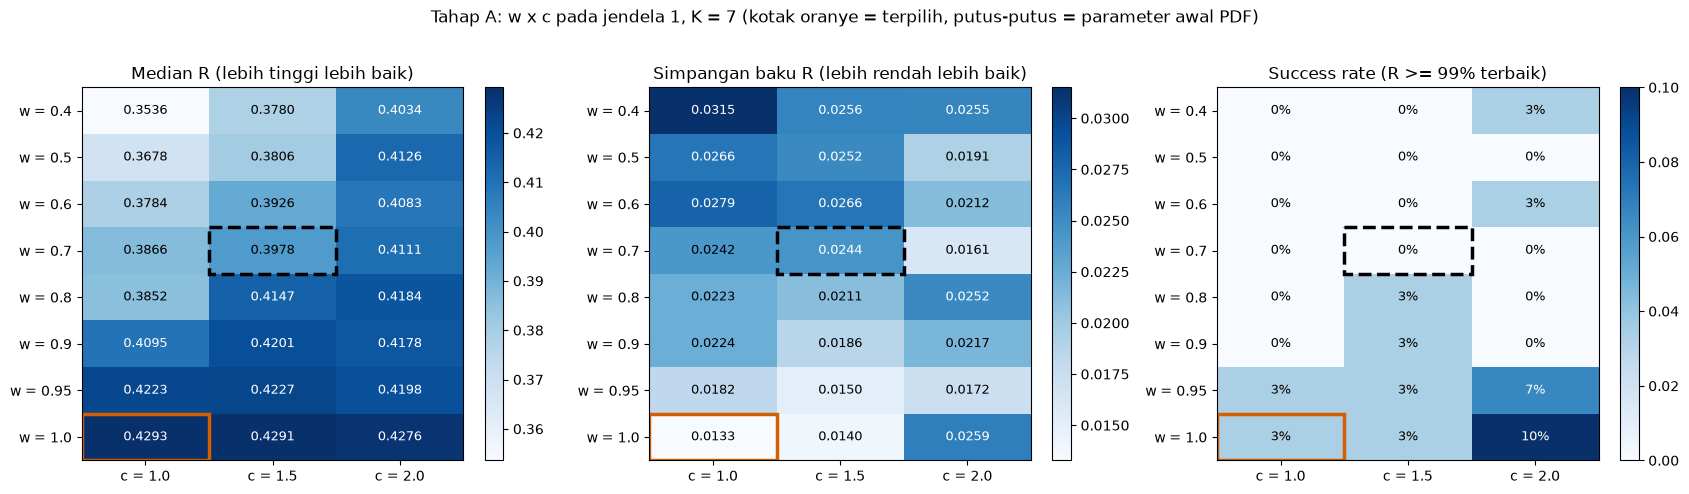

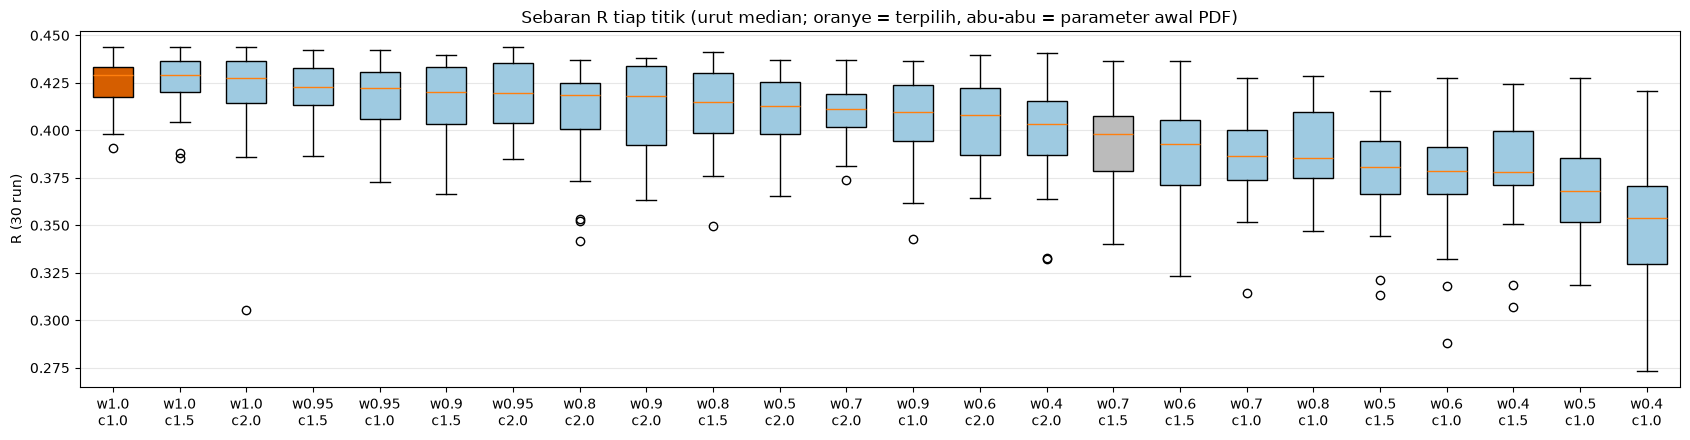

In [13]:
import warnings
warnings.simplefilter("ignore", RuntimeWarning)


def peta_panas(ax, tabel, kolom, judul, fmt, cmap="Blues"):
    pv = tabel.pivot(index="w", columns="c", values=kolom)
    im = ax.imshow(pv.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(pv.shape[1]), [f"c = {c}" for c in pv.columns]); ax.set_yticks(range(pv.shape[0]), [f"w = {w}" for w in pv.index])
    vmin, vmax = np.nanmin(pv.values), np.nanmax(pv.values)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v_ = pv.values[i, j]
            ax.text(j, i, fmt(v_), ha="center", va="center", fontsize=9, color="white" if (v_ - vmin) / (vmax - vmin + 1e-12) > 0.6 else "black")
    for (w_, c_, kunci, gaya) in [(best_A["w"], best_A["c"], "terpilih", "-"), (DEFAULT[0], DEFAULT[1], "awal PDF", "--")]:
        i, j = list(pv.index).index(w_), list(pv.columns).index(c_)
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="#D55E00" if gaya == "-" else "black", lw=2.5, ls=gaya))
    ax.set_title(judul); plt.colorbar(im, ax=ax, fraction=0.046)


fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
peta_panas(ax[0], tabel_A, "median", "Median R (lebih tinggi lebih baik)", lambda v: f"{v:.4f}")
peta_panas(ax[1], tabel_A, "std", "Simpangan baku R (lebih rendah lebih baik)", lambda v: f"{v:.4f}")
peta_panas(ax[2], tabel_A, "sukses", "Success rate (R >= 99% terbaik)", lambda v: f"{v:.0%}")
fig.suptitle("Tahap A: w x c pada jendela 1, K = 7 (kotak oranye = terpilih, putus-putus = parameter awal PDF)", y=1.02)
plt.tight_layout(); plt.show()

urut = tabel_A.sort_values("median", ascending=False)
fig, a_ = plt.subplots(figsize=(17, 4.5))
data = [[r.R if r.feasible else np.nan for r in hasil_A[(w_, c_, v_)]] for w_, c_, v_ in zip(urut["w"], urut["c"], urut["v_maks"])]
bp = a_.boxplot(data, patch_artist=True, widths=0.6, tick_labels=[f"w{w_}\nc{c_}" for w_, c_ in zip(urut["w"], urut["c"])])
for patch, w_, c_ in zip(bp["boxes"], urut["w"], urut["c"]):
    patch.set_facecolor("#D55E00" if (w_, c_) == (best_A["w"], best_A["c"]) else ("#bbbbbb" if (w_, c_) == DEFAULT[:2] else "#9ecae1"))
a_.set(title="Sebaran R tiap titik (urut median; oranye = terpilih, abu-abu = parameter awal PDF)", ylabel="R (30 run)")
a_.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

## 4. Tahap B: grid $v_{maks}$

Pada $(w, c)$ terbaik tahap A, $v_{maks}$ divariasikan. Batas kecepatan menentukan seberapa jauh partikel boleh meloncat dalam satu
langkah: terlalu kecil memperlambat pencarian, terlalu besar membuat partikel menabrak batas $[0,1]$ dan kecepatannya dinolkan.

  B: w = 1.0, c = 1.0, v_maks = 0.05  median R = 0.3884  std = 0.0318  layak = 100%


  B: w = 1.0, c = 1.0, v_maks = 0.1   median R = 0.4024  std = 0.0229  layak = 100%


  B: w = 1.0, c = 1.0, v_maks = 0.2   median R = 0.4293  std = 0.0133  layak = 100%


  B: w = 1.0, c = 1.0, v_maks = 0.5   median R = 0.4313  std = 0.0152  layak = 100%


  B: w = 1.0, c = 1.0, v_maks = 1.0   median R = 0.4315  std = 0.0143  layak = 100%
  selesai: 5 titik x 30 run dalam 37 detik

Tahap B pada w = 1.0, c = 1.0:

 v_maks  median   mean    std  minimum   maks  sukses  layak  awal50
 0.0500  0.3884 0.3859 0.0318   0.2909 0.4331  0.0000 1.0000  0.7667
 0.1000  0.4024 0.4018 0.0229   0.3548 0.4345  0.0000 1.0000  0.6333
 0.2000  0.4293 0.4239 0.0133   0.3906 0.4436  0.0333 1.0000  0.6667
 0.5000  0.4313 0.4248 0.0152   0.3806 0.4393  0.0333 1.0000  0.6000
 1.0000  0.4315 0.4264 0.0143   0.3755 0.4408  0.0667 1.0000  0.6000

Kruskal-Wallis atas 5 nilai v_maks: p = 2.28e-11  ->  v_maks berpengaruh nyata


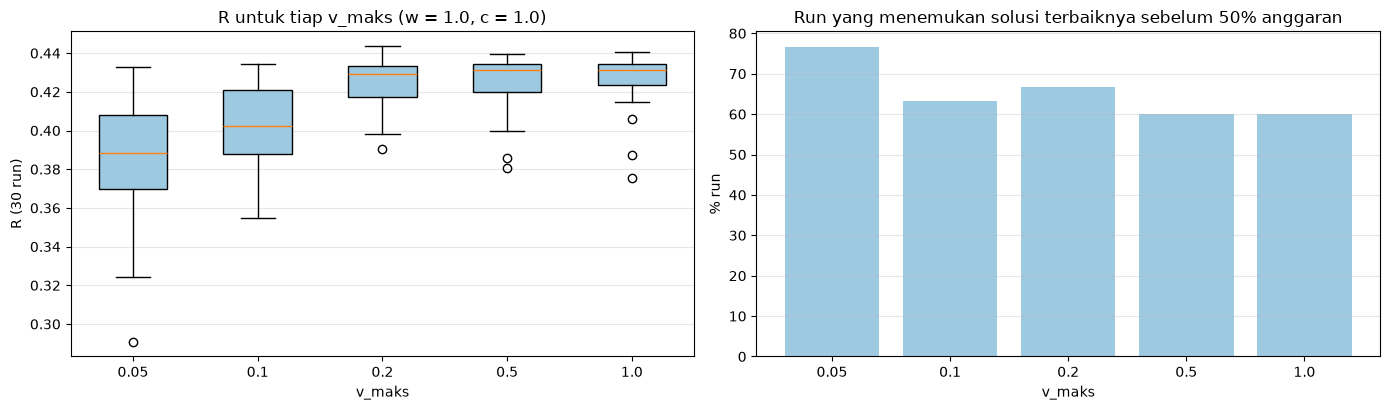

In [14]:
hasil_B = eksekusi([(float(best_A["w"]), float(best_A["c"]), v_) for v_ in [0.05, 0.1, 0.2, 0.5, 1.0]], "B")
R_ref_B = max(R_ref_A, max(r.R for runs in hasil_B.values() for r in runs if r.feasible))
tabel_B = ringkas(hasil_B, R_ref_B)
print(f"\nTahap B pada w = {best_A['w']}, c = {best_A['c']}:\n")
print(tabel_B[["v_maks", "median", "mean", "std", "minimum", "maks", "sukses", "layak", "awal50"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
H_b, p_kw_b = kruskal(*[[r.R if r.feasible else -1.0 for r in runs] for runs in hasil_B.values()])
print(f"\nKruskal-Wallis atas {len(hasil_B)} nilai v_maks: p = {p_kw_b:.3g}  ->  " + ("v_maks berpengaruh nyata" if p_kw_b < 0.05 else "v_maks TIDAK berpengaruh nyata"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
data = [[r.R if r.feasible else np.nan for r in hasil_B[k]] for k in hasil_B]
bp = ax[0].boxplot(data, patch_artist=True, widths=0.55, tick_labels=[f"{k[2]}" for k in hasil_B])
for patch in bp["boxes"]:
    patch.set_facecolor("#9ecae1")
ax[0].set(title=f"R untuk tiap v_maks (w = {best_A['w']}, c = {best_A['c']})", xlabel="v_maks", ylabel="R (30 run)"); ax[0].grid(axis="y", alpha=0.3)
ax[1].bar([str(v_) for v_ in tabel_B["v_maks"]], tabel_B["awal50"] * 100, color="#9ecae1")
ax[1].set(title="Run yang menemukan solusi terbaiknya sebelum 50% anggaran", xlabel="v_maks", ylabel="% run"); ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Seleksi dan pembekuan parameter

Konfigurasi akhir dipilih dari **seluruh** titik tahap A dan B dengan aturan yang sama (median R tertinggi; selisih ≤ 0,001 → simpangan baku
terkecil), lalu dibandingkan dengan parameter awal PDF pada seed penalaan yang sama. Parameter terpilih **dibekukan** untuk Fase 2.

In [15]:
import json

semua = {**hasil_A, **{k: v for k, v in hasil_B.items() if k not in hasil_A}}
R_ref_T = max(r.R for runs in semua.values() for r in runs if r.feasible)
tabel_T = ringkas(semua, R_ref_T)
terpilih = pilih(tabel_T)
PSO_TUNED = dict(w=float(terpilih["w"]), c1=float(terpilih["c"]), c2=float(terpilih["c"]), v_maks=float(terpilih["v_maks"]))
print(f"Parameter terpilih (dibekukan): w = {PSO_TUNED['w']}, c1 = c2 = {PSO_TUNED['c1']}, v_maks = {PSO_TUNED['v_maks']}   (swarm 40, 500 iterasi, anggaran 20.000)")

def Reff(runs):
    return np.array([r.R if r.feasible else -1.0 for r in runs])

rd, rt = Reff(semua[DEFAULT]), Reff(semua[(PSO_TUNED["w"], PSO_TUNED["c1"], PSO_TUNED["v_maks"])])
_, p_mw = mannwhitneyu(rt, rd, alternative="two-sided")
rng_b = np.random.default_rng(0)
boot = [np.median(rng_b.choice(rt, len(rt))) - np.median(rng_b.choice(rd, len(rd))) for _ in range(4000)]
ci = np.percentile(boot, [2.5, 97.5])

print(f"\n{'':<22}{'median R':>10}{'mean':>9}{'std':>9}{'min':>9}{'sukses<=1%':>12}{'terbaik <50% anggaran':>24}")
for nama, rr, kunci in [("parameter awal PDF", rd, DEFAULT), ("parameter terpilih", rt, (PSO_TUNED["w"], PSO_TUNED["c1"], PSO_TUNED["v_maks"]))]:
    row = tabel_T[(tabel_T.w == kunci[0]) & (tabel_T.c == kunci[1]) & (tabel_T.v_maks == kunci[2])].iloc[0]
    print(f"{nama:<22}{np.median(rr):>10.4f}{rr.mean():>9.4f}{rr.std():>9.4f}{rr.min():>9.4f}{row['sukses']:>12.0%}{row['awal50']:>24.0%}")
print(f"\nSelisih median (terpilih - awal) = {np.median(rt) - np.median(rd):+.4f}, selang kepercayaan 95% bootstrap [{ci[0]:+.4f}, {ci[1]:+.4f}], Mann-Whitney p = {p_mw:.3g}")
print("  ->  " + ("perbaikan nyata pada data penalaan" if p_mw < 0.05 else "perbedaan TIDAK nyata pada data penalaan") +
      " (catatan: data penalaan bias ke atas karena 'kutukan pemenang'; lihat validasi di bagian 6)")

# seberapa tajam optimumnya? konfigurasi lain yang tidak berbeda nyata dari yang terpilih (uji berpasangan, tanpa koreksi: hanya indikatif)
kunci_t = (PSO_TUNED["w"], PSO_TUNED["c1"], PSO_TUNED["v_maks"])
p_lain = {k: mannwhitneyu(Reff(runs), rt, alternative="two-sided")[1] for k, runs in semua.items() if k != kunci_t}
n_setara = sum(p >= 0.05 for p in p_lain.values())
print(f"\nKonfigurasi lain yang TIDAK berbeda nyata dari yang terpilih (Mann-Whitney p >= 0,05): {n_setara} dari {len(p_lain)}")
setara = sorted([(k, p) for k, p in p_lain.items() if p >= 0.05], key=lambda kp: -np.median(Reff(semua[kp[0]])))[:8]
for (w_, c_, v_), p in setara:
    print(f"   w = {w_:<5} c = {c_:<4} v_maks = {v_:<5} median R = {np.median(Reff(semua[(w_, c_, v_)])):.4f}   p = {p:.2f}")
print("  ->  penalaan mengenali WILAYAH parameter yang baik, bukan satu titik tunggal.")

# simpan hasil: grid (format long) dan parameter beku
df_long = pd.concat([ke_long({k: v for k, v in hasil_A.items() if k not in kunci_A2}, "A"),
                     ke_long({k: v for k, v in hasil_A.items() if k in kunci_A2}, "A2"),
                     ke_long(hasil_B, "B")], ignore_index=True)
print("\ngrid disimpan ke:", simpan(df_long, "pso_fase1_grid.csv"))
beku = dict(PSO_TUNED, swarm=PSO_PARAM["n"], iterasi=BUDGET // PSO_PARAM["n"], anggaran=BUDGET, data_penalaan=DATA_TUNING, K=K_TUNING,
            seed_penalaan=[SEED_TUNING[0], SEED_TUNING[-1]], median_R_penalaan=float(np.median(rt)), aturan="median R tertinggi; selisih <= 0,001 -> std terkecil")
try:
    (ROOT / "hasil" / "csv" / "pso_parameter_beku.json").write_text(json.dumps(beku, indent=2, ensure_ascii=False), encoding="utf-8")
    print("parameter beku disimpan ke:", ROOT / "hasil" / "csv" / "pso_parameter_beku.json")
except Exception as e:
    print("(gagal menyimpan parameter beku:", e, ")")

Parameter terpilih (dibekukan): w = 1.0, c1 = c2 = 1.0, v_maks = 1.0   (swarm 40, 500 iterasi, anggaran 20.000)

                        median R     mean      std      min  sukses<=1%   terbaik <50% anggaran
parameter awal PDF        0.3978   0.3945   0.0244   0.3403          0%                     83%
parameter terpilih        0.4315   0.4264   0.0143   0.3755          7%                     60%

Selisih median (terpilih - awal) = +0.0336, selang kepercayaan 95% bootstrap [+0.0271, +0.0460], Mann-Whitney p = 1.02e-06
  ->  perbaikan nyata pada data penalaan (catatan: data penalaan bias ke atas karena 'kutukan pemenang'; lihat validasi di bagian 6)

Konfigurasi lain yang TIDAK berbeda nyata dari yang terpilih (Mann-Whitney p >= 0,05): 7 dari 27
   w = 1.0   c = 1.0  v_maks = 0.5   median R = 0.4313   p = 0.89
   w = 1.0   c = 1.0  v_maks = 0.2   median R = 0.4293   p = 0.34
   w = 1.0   c = 1.5  v_maks = 0.2   median R = 0.4291   p = 0.99
   w = 1.0   c = 2.0  v_maks = 0.2   median R 

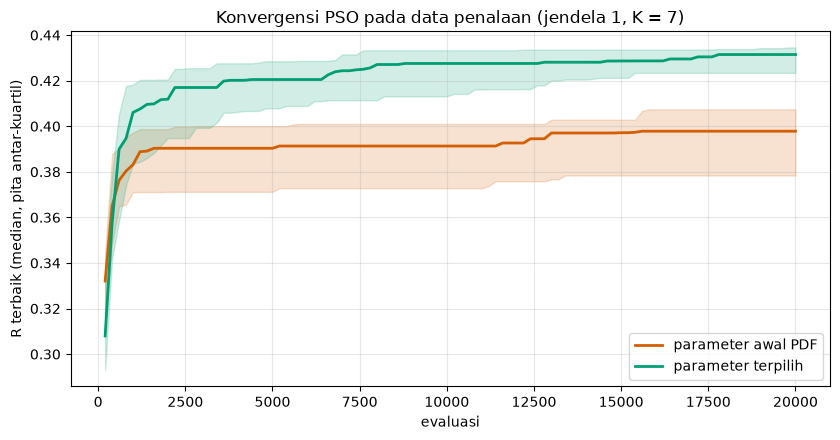

In [16]:
# kurva konvergensi pada data penalaan: awal PDF vs terpilih (median dan pita antar-kuartil)
fig, a_ = plt.subplots(figsize=(8.5, 4.5))
for nama, kunci, warna in [("parameter awal PDF", DEFAULT, "#D55E00"), ("parameter terpilih", (PSO_TUNED["w"], PSO_TUNED["c1"], PSO_TUNED["v_maks"]), "#009E73")]:
    runs = semua[kunci]
    Hh = np.array([[h[1] for h in r.history] for r in runs]); x_ = [h[0] for h in runs[0].history]
    a_.fill_between(x_, np.nanpercentile(Hh, 25, 0), np.nanpercentile(Hh, 75, 0), color=warna, alpha=0.18)
    a_.plot(x_, np.nanmedian(Hh, 0), color=warna, lw=2, label=nama)
a_.set(title="Konvergensi PSO pada data penalaan (jendela 1, K = 7)", xlabel="evaluasi", ylabel="R terbaik (median, pita antar-kuartil)")
a_.legend(); a_.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 6. Validasi pada data lain

Parameter terpilih diuji pada **data, K, dan seed yang tidak dipakai penalaan**: kasus tetap, $K \in \{2,3,5,7,10\}$, seed 0 sampai 29.
PSO parameter awal, PSO parameter terpilih, dan **GA** (parameter awal PDF; GA belum ditala) dijalankan pada masalah dan anggaran yang sama.
R acuan: optimum brute force untuk K = 2, selain itu solusi terbaik di antara semua run ketiga algoritma (gap = terhadap *yang terbaik diketahui*).

In [17]:
DATA_VAL = "kasus_tetap"
SEED_VAL = list(range(30))
ALGO = {"PSO awal": lambda P, s: pso_run(P, seed=s),
        "PSO terpilih": lambda P, s: pso_run(P, seed=s, **PSO_TUNED),
        "GA": lambda P, s: ga_run(P, seed=s)}
WARNA3 = {"PSO awal": "#D55E00", "PSO terpilih": "#009E73", "GA": "#0072B2"}

val = {K: {nama: [f(buat_problem(DATA[DATA_VAL], K), s) for s in SEED_VAL] for nama, f in ALGO.items()} for K in K_LIST}
BF_VAL = brute_force_k2(buat_problem(DATA[DATA_VAL], 2))["kas bebas"][0]

baris = []
for K in K_LIST:
    semua_R = [r.R for runs in val[K].values() for r in runs if r.feasible]
    R_ref, sumber = (BF_VAL, "brute force") if K == 2 else (max(semua_R), "terbaik diketahui")
    Rv = {nama: np.array([r.R if r.feasible else -1.0 for r in runs]) for nama, runs in val[K].items()}
    _, p_td = mannwhitneyu(Rv["PSO terpilih"], Rv["PSO awal"], alternative="two-sided")
    _, p_tg = mannwhitneyu(Rv["PSO terpilih"], Rv["GA"], alternative="two-sided")
    def nyata(a, b, p):
        return "tidak berbeda nyata" if p >= 0.05 else (a if np.median(Rv[a]) > np.median(Rv[b]) else b)
    baris.append({"K": K, "R acuan": f"{R_ref:.4f} ({sumber})",
                  "median PSO awal": f"{np.median(Rv['PSO awal']):.4f}", "median PSO terpilih": f"{np.median(Rv['PSO terpilih']):.4f}", "median GA": f"{np.median(Rv['GA']):.4f}",
                  "sukses<=1% (awal / terpilih / GA)": " / ".join(f"{np.mean(Rv[n] >= R_ref * 0.99):.0%}" for n in ["PSO awal", "PSO terpilih", "GA"]),
                  "terpilih vs awal": nyata("PSO terpilih", "PSO awal", p_td) + f" (p={p_td:.2g})",
                  "terpilih vs GA": nyata("PSO terpilih", "GA", p_tg) + f" (p={p_tg:.2g})"})
tabel_val = pd.DataFrame(baris)
print(f"Validasi pada {DATA_VAL}: 30 seed per K (seed 0..29), anggaran {BUDGET:,} evaluasi\n")
print(tabel_val.to_string(index=False))
print("\nwaktu rata-rata per run: " + " | ".join(f"{n} {np.mean([r.seconds for K in K_LIST for r in val[K][n]]):.2f} detik" for n in ALGO))

Validasi pada kasus_tetap: 30 seed per K (seed 0..29), anggaran 20,000 evaluasi

 K                    R acuan median PSO awal median PSO terpilih median GA sukses<=1% (awal / terpilih / GA)         terpilih vs awal                terpilih vs GA
 2       0.2966 (brute force)          0.2736              0.2950    0.2963                   47% / 80% / 73%  PSO terpilih (p=0.0036)  tidak berbeda nyata (p=0.19)
 3 0.3223 (terbaik diketahui)          0.3038              0.3124    0.3010                     7% / 40% / 3% PSO terpilih (p=1.1e-05)      PSO terpilih (p=7.5e-05)
 5 0.3408 (terbaik diketahui)          0.3059              0.3311    0.3333                    7% / 17% / 10% PSO terpilih (p=0.00038) tidak berbeda nyata (p=0.089)
 7 0.3413 (terbaik diketahui)          0.3048              0.3339    0.3372                     0% / 7% / 30% PSO terpilih (p=2.2e-07)                GA (p=7.6e-05)
10 0.3402 (terbaik diketahui)          0.3165              0.3358    0.3162                   

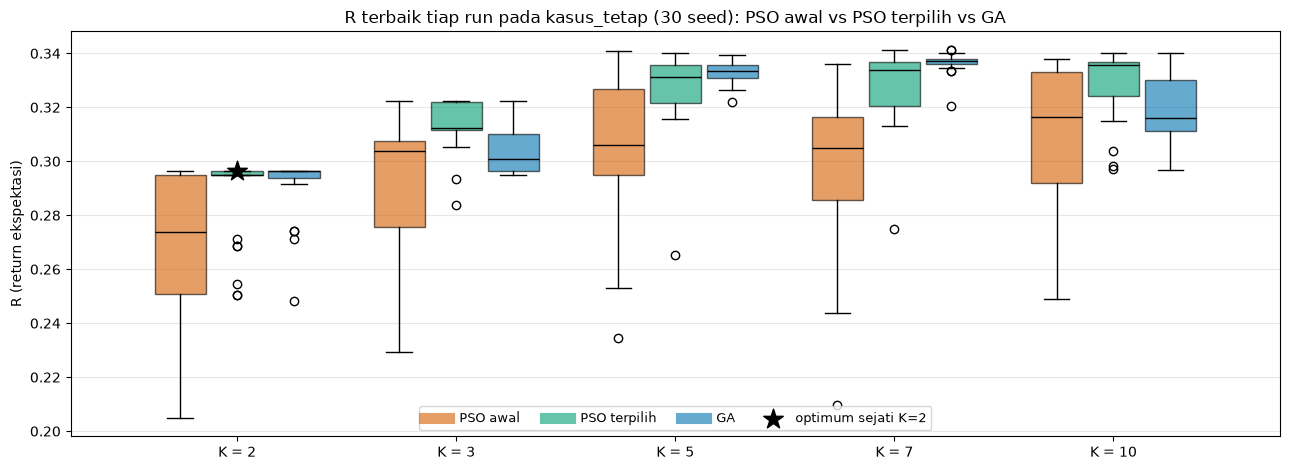

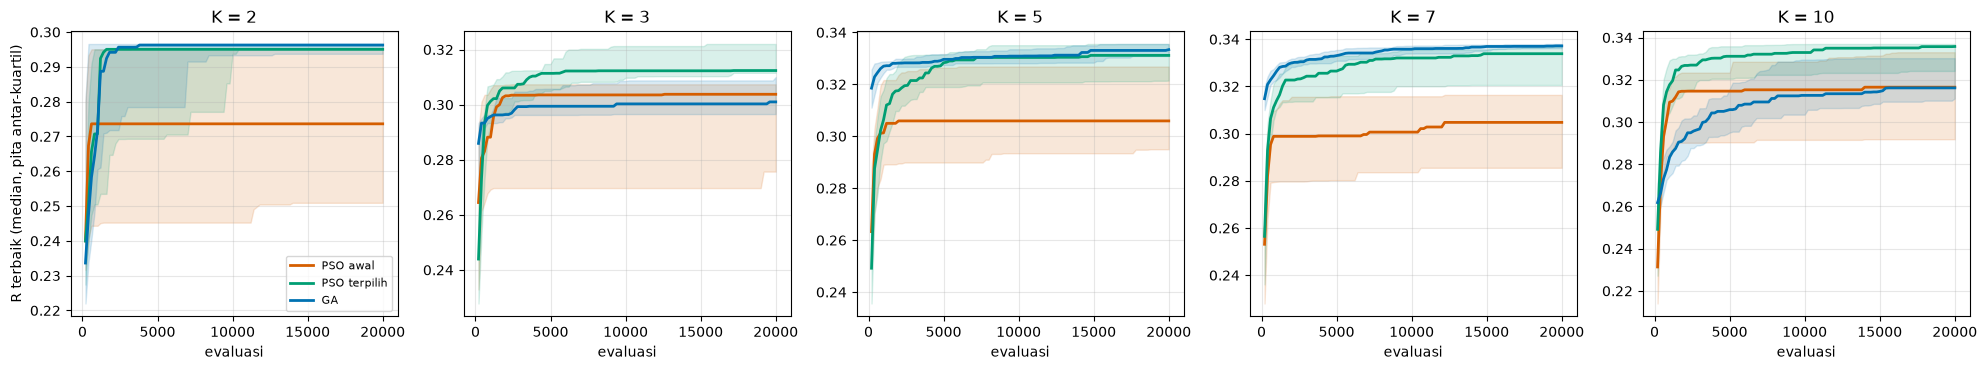

In [18]:
fig, a_ = plt.subplots(figsize=(13, 4.8))
pos = np.arange(len(K_LIST)); lebar = 0.26
for k_, (nama, warna) in enumerate(WARNA3.items()):
    data = [[r.R for r in val[K][nama] if r.feasible] for K in K_LIST]
    bp = a_.boxplot(data, positions=pos + (k_ - 1) * lebar, widths=lebar * 0.9, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor(warna); patch.set_alpha(0.6)
    for med in bp["medians"]:
        med.set_color("black")
    a_.plot([], [], color=warna, lw=8, alpha=0.6, label=nama)
a_.scatter([0], [BF_VAL], marker="*", s=220, color="black", zorder=6, label="optimum sejati K=2")
a_.set_xticks(pos, [f"K = {K}" for K in K_LIST]); a_.set(title=f"R terbaik tiap run pada {DATA_VAL} (30 seed): PSO awal vs PSO terpilih vs GA", ylabel="R (return ekspektasi)")
a_.legend(fontsize=9, ncol=4, loc="lower center"); a_.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(K_LIST), figsize=(4 * len(K_LIST), 3.8))
for a_, K in zip(axes, K_LIST):
    for nama, warna in WARNA3.items():
        runs = val[K][nama]
        Hh = np.array([[h[1] for h in r.history] for r in runs]); x_ = [h[0] for h in runs[0].history]
        a_.fill_between(x_, np.nanpercentile(Hh, 25, 0), np.nanpercentile(Hh, 75, 0), color=warna, alpha=0.15)
        a_.plot(x_, np.nanmedian(Hh, 0), color=warna, lw=2, label=nama)
    a_.set(title=f"K = {K}", xlabel="evaluasi"); a_.grid(alpha=0.3)
axes[0].set_ylabel("R terbaik (median, pita antar-kuartil)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [19]:
# K = 2 pada tiga data: seberapa sering tiap algoritma mencapai optimum sejati (gap <= 1%)?
print(f"{'data':<13}{'R* (brute force)':>18}" + "".join(f"{n:>26}" for n in ALGO))
sukses_k2 = {n: [] for n in ALGO}
for nama_data in ["kasus_tetap", "jendela_3", "jendela_5"]:
    P2 = buat_problem(DATA[nama_data], 2)
    Rstar = brute_force_k2(P2)["kas bebas"][0]
    baris = f"{nama_data:<13}{Rstar:>18.4f}"
    for n, f in ALGO.items():
        runs = val[2][n] if nama_data == DATA_VAL else [f(P2, s) for s in SEED_VAL]
        ok = np.mean([(r.feasible and r.R >= Rstar * 0.99) for r in runs]); tepat = np.mean([(r.feasible and r.R >= Rstar - 1e-9) for r in runs])
        sukses_k2[n].append(ok)
        baris += f"{f'{ok:.0%} (tepat {tepat:.0%})':>26}"
    print(baris)

data           R* (brute force)                  PSO awal              PSO terpilih                        GA
kasus_tetap              0.2966            47% (tepat 3%)           80% (tepat 23%)           73% (tepat 37%)


jendela_3                0.2817           37% (tepat 37%)           70% (tepat 70%)           60% (tepat 60%)


jendela_5                0.5114           47% (tepat 13%)           83% (tepat 70%)           97% (tepat 70%)


## 7. Kesimpulan

Teks di bawah dihitung dari hasil notebook ini.

In [20]:
from IPython.display import Markdown, display

n_titik = len(semua)
n_A, n_B = len(hasil_A), len(hasil_B)
w_lo, w_hi = min(k[0] for k in semua), max(k[0] for k in semua)
c_lo, c_hi = min(k[1] for k in semua), max(k[1] for k in semua)
v_lo, v_hi = min(k[2] for k in semua), max(k[2] for k in semua)
tepi_akhir = []
if PSO_TUNED["w"] >= 1.0: tepi_akhir.append("w = %.2f adalah batas praktis atas (w > 1 tidak meredam kecepatan), sehingga tidak diperluas lagi" % PSO_TUNED["w"])
elif PSO_TUNED["w"] >= w_hi: tepi_akhir.append("w = %.2f di batas atas grid" % PSO_TUNED["w"])
if PSO_TUNED["w"] <= w_lo: tepi_akhir.append("w = %.2f di batas bawah grid" % PSO_TUNED["w"])
if PSO_TUNED["c1"] >= c_hi: tepi_akhir.append("c = %.1f di batas atas grid" % PSO_TUNED["c1"])
if PSO_TUNED["c1"] <= c_lo: tepi_akhir.append("c = %.1f di batas bawah grid" % PSO_TUNED["c1"])
if PSO_TUNED["v_maks"] >= v_hi: tepi_akhir.append("v_maks = %.2f di batas atas grid" % PSO_TUNED["v_maks"])
if PSO_TUNED["v_maks"] <= v_lo: tepi_akhir.append("v_maks = %.2f di batas bawah grid" % PSO_TUNED["v_maks"])
catatan_tepi = ("Parameter terpilih berada di tepi grid: " + "; ".join(tepi_akhir) + ". Optimum pada parameter yang bukan w bisa berada di luar grid; "
                "kecenderungan ke tepi ini perlu dicatat di laporan."
                if tepi_akhir else "Parameter terpilih berada di dalam grid (bukan di tepi), sehingga tidak ada indikasi optimum tertinggal di luar grid.")
med_awal, med_pilih = float(np.median(rd)), float(np.median(rt))
sens_w = tabel_A.groupby("w")["median"].median(); sens_c = tabel_A.groupby("c")["median"].median()
rentang_w, rentang_c = float(sens_w.max() - sens_w.min()), float(sens_c.max() - sens_c.min())
paling = "inersia w" if rentang_w > rentang_c else "koefisien c"
w_terbaik_w, c_terbaik_c = sens_w.idxmax(), sens_c.idxmax()
dini_awal = float(tabel_T[(tabel_T.w == DEFAULT[0]) & (tabel_T.c == DEFAULT[1]) & (tabel_T.v_maks == DEFAULT[2])]["awal50"].iloc[0])
dini_pilih = float(tabel_T[(tabel_T.w == PSO_TUNED["w"]) & (tabel_T.c == PSO_TUNED["c1"]) & (tabel_T.v_maks == PSO_TUNED["v_maks"])]["awal50"].iloc[0])

mdn = {K: {n: float(np.median([r.R for r in val[K][n] if r.feasible])) for n in ALGO} for K in K_LIST}
selisih_td = {K: mdn[K]["PSO terpilih"] - mdn[K]["PSO awal"] for K in K_LIST}
lebih_baik_td = sum(v > 0.0005 for v in selisih_td.values()); lebih_buruk_td = sum(v < -0.0005 for v in selisih_td.values())
kalah_ga = [K for K in K_LIST if mdn[K]["GA"] > mdn[K]["PSO terpilih"] + 0.0005]
menang_ga = [K for K in K_LIST if mdn[K]["PSO terpilih"] > mdn[K]["GA"] + 0.0005]
tabel_val["tv_ga"] = tabel_val["terpilih vs GA"]
n_ga_nyata = sum(s.startswith("GA") for s in tabel_val["tv_ga"]); n_pso_nyata = sum(s.startswith("PSO terpilih") for s in tabel_val["tv_ga"])
n_td_nyata = sum(s.startswith("PSO terpilih") for s in tabel_val["terpilih vs awal"]); n_td_buruk = sum(s.startswith("PSO awal") for s in tabel_val["terpilih vs awal"])
ok2 = {n: np.mean(v) for n, v in sukses_k2.items()}

butir = [
    ("**1. Parameter yang dibekukan.** Dari %d titik (tahap A w x c: %d titik termasuk perluasan; tahap B v_maks: %d titik) x 30 run pada jendela 1, K = 7, "
     "konfigurasi terpilih adalah **w = %.2f, c1 = c2 = %.1f, v_maks = %.2f** (swarm 40, 500 iterasi). Parameter awal PDF adalah w = %.1f, c = %.1f, v_maks = %.1f. %s"
     % (n_titik, n_A, n_B, PSO_TUNED["w"], PSO_TUNED["c1"], PSO_TUNED["v_maks"], DEFAULT[0], DEFAULT[1], DEFAULT[2], catatan_tepi)),
    ("**2. Apakah penalaan berpengaruh?** Uji Kruskal-Wallis pada tahap A memberi p = %.3g (%s). Pada data penalaan, median R naik dari %.4f (parameter awal) "
     "menjadi %.4f (terpilih), selisih %+.4f (selang 95%% bootstrap [%+.4f, %+.4f], Mann-Whitney p = %.3g). Parameter yang paling menentukan adalah %s "
     "(rentang median antar nilai %.4f untuk w vs %.4f untuk c; w terbaik %.1f, c terbaik %.1f). Persen run yang menemukan solusi terbaiknya sebelum separuh "
     "anggaran berubah dari %.0f%% menjadi %.0f%%. Dari %d konfigurasi lain, %d tidak berbeda nyata dari yang terpilih (uji berpasangan tanpa koreksi): "
     "penalaan mengenali wilayah parameter yang baik, bukan satu titik tunggal."
     % (p_kw, "pilihan (w, c) berpengaruh nyata" if p_kw < 0.05 else "pilihan (w, c) tidak berpengaruh nyata", med_awal, med_pilih, med_pilih - med_awal,
        ci[0], ci[1], p_mw, paling, rentang_w, rentang_c, w_terbaik_w, c_terbaik_c, dini_awal * 100, dini_pilih * 100, len(p_lain), n_setara)),
    ("**3. Validasi pada data lain (%s, seed 0-29).** PSO terpilih lebih baik dari PSO awal pada %d dari %d nilai K (secara nyata pada %d; lebih buruk secara nyata pada %d). "
     "Dibanding GA (parameter awal PDF, belum ditala), GA lebih baik secara nyata pada %d dari %d K dan PSO terpilih pada %d. Pada K = 2, success rate (gap <= 1%% dari optimum sejati) "
     "rata-rata pada tiga data: PSO awal %.0f%%, PSO terpilih %.0f%%, GA %.0f%%."
     % (DATA_VAL, lebih_baik_td, len(K_LIST), n_td_nyata, n_td_buruk, n_ga_nyata, len(K_LIST), n_pso_nyata, ok2["PSO awal"] * 100, ok2["PSO terpilih"] * 100, ok2["GA"] * 100)),
]
if lebih_baik_td >= 3 and n_ga_nyata <= 1:
    butir.append("**4. Penilaian.** Penalaan memperbaiki PSO dan menutup sebagian besar jarak dengan GA. Parameter ini layak dibekukan untuk Fase 2.")
elif lebih_baik_td >= 3:
    butir.append("**4. Penilaian.** Penalaan memperbaiki PSO, tetapi GA masih lebih baik secara nyata pada sebagian K. Parameter ini layak dibekukan untuk Fase 2 (PSO dibandingkan "
                 "dengan GA yang juga ditala agar adil), dan PSO baku (w, c tetap) tampaknya terbatas oleh pemetaan kunci ke himpunan saham.")
else:
    butir.append("**4. Penilaian.** Penalaan w, c, dan v_maks **tidak** menghasilkan perbaikan yang konsisten pada data validasi, sehingga kelemahan PSO pada masalah ini bersifat "
                 "struktural (konvergen dini akibat pemetaan kunci ke himpunan saham), bukan soal parameter. Parameter terpilih tetap dibekukan agar Fase 2 sesuai PDF, "
                 "tetapi perlu diberi tahu di laporan bahwa PSO baku berkinerja lebih rendah dari GA. Varian di luar PDF (bobot inersia menurun, topologi lokal/cincin, "
                 "atau restart saat stagnasi) layak dicoba sebagai ekstensi.")
if PSO_TUNED["w"] >= 0.95:
    butir.append("**Tafsir.** Konfigurasi terpilih memakai inersia sangat tinggi (w = %.2f) sehingga kecepatan hampir tidak diredam dan swarm tidak cepat mengerucut. "
                 "Perbaikannya berasal dari berkurangnya tekanan konvergensi, yang sejalan dengan penanda konvergen dini pada PSO baku (parameter awal PDF): "
                 "pada masalah dengan pemetaan kunci ke himpunan saham yang tidak mulus, PSO bekerja paling baik bila ia lebih menyerupai pencarian acak berinersia "
                 "daripada pencarian yang cepat konvergen. Ini juga alasan varian di luar PDF (inersia menurun, topologi lokal) layak dicoba." % PSO_TUNED["w"])
butir.append("**5. Catatan metodologi.** Penalaan hanya memakai data latih jendela 1 (tanpa data uji), seed penalaan (100-129) berbeda dari seed evaluasi (0-29), dan validasi memakai data serta K "
             "yang berbeda untuk menghindari 'kutukan pemenang'. GA belum ditala di Fase 1; perbandingan PSO-GA yang final membutuhkan GA yang diperlakukan sama.")
display(Markdown("\n\n".join(butir)))

**1. Parameter yang dibekukan.** Dari 28 titik (tahap A w x c: 24 titik termasuk perluasan; tahap B v_maks: 5 titik) x 30 run pada jendela 1, K = 7, konfigurasi terpilih adalah **w = 1.00, c1 = c2 = 1.0, v_maks = 1.00** (swarm 40, 500 iterasi). Parameter awal PDF adalah w = 0.7, c = 1.5, v_maks = 0.2. Parameter terpilih berada di tepi grid: w = 1.00 adalah batas praktis atas (w > 1 tidak meredam kecepatan), sehingga tidak diperluas lagi; c = 1.0 di batas bawah grid; v_maks = 1.00 di batas atas grid. Optimum pada parameter yang bukan w bisa berada di luar grid; kecenderungan ke tepi ini perlu dicatat di laporan.

**2. Apakah penalaan berpengaruh?** Uji Kruskal-Wallis pada tahap A memberi p = 4.28e-30 (pilihan (w, c) berpengaruh nyata). Pada data penalaan, median R naik dari 0.3978 (parameter awal) menjadi 0.4315 (terpilih), selisih +0.0336 (selang 95% bootstrap [+0.0271, +0.0460], Mann-Whitney p = 1.02e-06). Parameter yang paling menentukan adalah inersia w (rentang median antar nilai 0.0511 untuk w vs 0.0293 untuk c; w terbaik 1.0, c terbaik 2.0). Persen run yang menemukan solusi terbaiknya sebelum separuh anggaran berubah dari 83% menjadi 60%. Dari 27 konfigurasi lain, 7 tidak berbeda nyata dari yang terpilih (uji berpasangan tanpa koreksi): penalaan mengenali wilayah parameter yang baik, bukan satu titik tunggal.

**3. Validasi pada data lain (kasus_tetap, seed 0-29).** PSO terpilih lebih baik dari PSO awal pada 5 dari 5 nilai K (secara nyata pada 5; lebih buruk secara nyata pada 0). Dibanding GA (parameter awal PDF, belum ditala), GA lebih baik secara nyata pada 1 dari 5 K dan PSO terpilih pada 2. Pada K = 2, success rate (gap <= 1% dari optimum sejati) rata-rata pada tiga data: PSO awal 43%, PSO terpilih 78%, GA 77%.

**4. Penilaian.** Penalaan memperbaiki PSO dan menutup sebagian besar jarak dengan GA. Parameter ini layak dibekukan untuk Fase 2.

**Tafsir.** Konfigurasi terpilih memakai inersia sangat tinggi (w = 1.00) sehingga kecepatan hampir tidak diredam dan swarm tidak cepat mengerucut. Perbaikannya berasal dari berkurangnya tekanan konvergensi, yang sejalan dengan penanda konvergen dini pada PSO baku (parameter awal PDF): pada masalah dengan pemetaan kunci ke himpunan saham yang tidak mulus, PSO bekerja paling baik bila ia lebih menyerupai pencarian acak berinersia daripada pencarian yang cepat konvergen. Ini juga alasan varian di luar PDF (inersia menurun, topologi lokal) layak dicoba.

**5. Catatan metodologi.** Penalaan hanya memakai data latih jendela 1 (tanpa data uji), seed penalaan (100-129) berbeda dari seed evaluasi (0-29), dan validasi memakai data serta K yang berbeda untuk menghindari 'kutukan pemenang'. GA belum ditala di Fase 1; perbandingan PSO-GA yang final membutuhkan GA yang diperlakukan sama.

**Langkah berikut:**

1. Menala GA (populasi × laju mutasi), SA ($T_0$ × laju pendinginan), dan DE ($F$ × $CR$) dengan prosedur Fase 1 yang sama, agar perbandingan adil.
2. Fase 2: 30 masalah (5 jendela + kasus tetap, × K) × 30 seed dengan semua parameter beku, lalu uji statistik antar-masalah (Wilcoxon + Holm).
3. Solver eksak SCIP untuk mengukur gap pada K = 7 dan 10.